# Можно ли доверять языковым моделям в задачах машинного обучения

## Что мы хотели узнать

Мы сравнили четыре языковые модели — YandexGPT, Qwen3-4B, GigaChat-2 и DeepSeek. Это программы, которые по тексту вопроса генерируют текст ответа. Мы проверяли, могут ли они правильно решать учебные задачи по машинному обучению, писать работающий код и определять класс объекта по числовым признакам.

Наша проверка состоит из трёх шагов: **задать одинаковые вопросы → сохранить первые ответы → сравнить их с заранее подготовленными правильными ответами**. Красивое объяснение и высокая заявленная уверенность сами по себе не считаются правильным решением.

## Как читать этот блокнот

Перед каждым вычислительным блоком объясняется его задача. После результатов описано, что означают числа. У каждого рисунка есть отдельные пояснения к осям, обозначениям и выводам. Код можно не разбирать с первого чтения: основной ход исследования понятен из текста, таблиц и рисунков. Технические подробности полезны, если преподаватель попросит проверить конкретное число.

Обычный **Run All** читает сохранённые данные, пересчитывает показатели и заново обучает простые классические модели. Запросы к языковым моделям при этом не отправляются. Последняя live-ячейка — отдельная, выключенная по умолчанию проверка подключения.

## Что получилось в общих чертах

DeepSeek правильно ответил на все 24 автоматически проверяемые задачи банка, но в классификации не завершил 138 из 300 запросов. Qwen оказалась конкурентной при классификации с примерами, хотя ошибалась в расчётных задачах. Простая логистическая регрессия на 20 примерах дала F1 около 0.912. Ни одна из этих фраз не означает, что одна модель лучше во всём: дальше мы разберём, **что именно измерено и где заканчиваются наши выводы**.

В блокноте сохраняется честный статус ручной проверки: оценки двух независимых людей по C/D и обоснованиям B ещё не зафиксированы. Поэтому итоговая «точность по всем 39 задачам» не придумывается.

### Минимальный словарь

| Термин | Простое объяснение |
|---|---|
| Модель | Программа, которая по входным данным выдаёт ответ или прогноз |
| Признак | Измеренная характеристика объекта, например числовой размер |
| Класс | Категория объекта; в нашем опыте это метка 0 или 1 |
| Обучающая выборка, train | Примеры с правильными метками, доступные при подготовке прогноза |
| Тестовая выборка, test | Отдельные примеры для проверки; их правильные метки модели не показываются |
| Эталон | Заранее подготовленный правильный ответ для сравнения |
| Baseline | Простое решение, с которым сравнивают более сложные модели |
| Accuracy, точность | Доля правильных ответов среди всех оцениваемых случаев |
| Coverage, покрытие | Доля случаев, где вообще получен допустимый ответ |
| F1 | Показатель качества поиска класса 1, учитывающий ложные тревоги и пропуски; подробнее в разделе 7 |
| Гипотеза | Проверяемое предположение о результате, сформулированное заранее |
| Доверительный интервал | Оценка неопределённости результата при заданных данных и методе расчёта |
| Токен | Фрагмент текста, которым оперирует модель и по которому обычно считают расход API |

Для короткой защиты: разделы **2 → 5 → 7 → 8 → 10 → 11 → 13**. Подробный личный разбор также сохранён в `docs/defense_guide.html` и PDF.


## 1 Подключение и пересчёт

Окружение: `pip install -r requirements-defense.txt`. Для Run All не нужны CUDA, веса или API-ключи. HTTP-транспорты во время анализа блокируются программно. Основные вычисления находятся в `scripts/defense_analysis.py`; ниже также вынесены показательные формулы и статистические расчёты.

**Что делает первый вычислительный блок.** Он находит папку проекта, подключает библиотеки и запускает пересчёт по сохранённым файлам. `numpy` выполняет численные операции, `pandas` показывает таблицы. `analyze()` заново проверяет ответы и рассчитывает результаты; `offline()` запрещает сетевые обращения во время этого пересчёта. Вспомогательные `table`, `show` и `figure` далее выводят таблицу, технический объект с данными или рисунок.

**Зачем это нужно.** Результат не должен существовать только в виде вручную написанных процентов. Мы должны уметь восстановить его из исходных ответов.

In [1]:
from pathlib import Path
import sys,json,csv,html,inspect,hashlib
import numpy as np
import pandas as pd
from IPython.display import display,HTML,Image
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'scripts/defense_analysis.py').exists())
sys.path.insert(0,str(ROOT/'scripts'))
from defense_analysis import analyze,audit,offline,baselines,load_model,MODELS,confusion
from analysis_common import read_json,read_lines,raw_text,auto_correct,accuracy_ci,h12_comparison
from defense_display import table as readable_table, hypotheses as readable_hypotheses, cases as readable_cases, manual as readable_manual
OUT=ROOT/'analysis/defense'
with offline():summary=analyze(ROOT)
def table(name):readable_table(OUT,name)
def show(name):print(json.dumps(read_json(OUT/name),ensure_ascii=False,indent=2))
def figure(name):display(Image(filename=str(OUT/'figures'/name)))
show('summary.json')

{
  "models": 4,
  "responses": 1376,
  "pilot": 20,
  "evaluated_requests": 1356,
  "ABF_tasks_per_model": 24,
  "classification_rows_per_shots": 100,
  "manual_reviews_pending": true,
  "overall_39_accuracy": null,
  "analysis_api_calls": 0,
  "generated_code_executions": 0,
  "seed": 42,
  "bootstrap_draws": 1000
}


**Как понимать сводку.** `models=4` — число сравниваемых моделей. `responses=1376` — все сохранённые ответы, включая 20 пилотных. `evaluated_requests=1356` — основные запросы без пилота. Это ещё не единый знаменатель качества: разные типы задач оцениваются отдельно. Нули в `analysis_api_calls` и `generated_code_executions` означают, что сейчас не вызывались LLM и не исполнялись программы из их ответов. Обучение наших собственных простых baseline при этом выполняется.

`overall_39_accuracy=null` означает «общая оценка пока не определена», а не «модель решила ноль задач». Причина — незаполненная независимая ручная проверка.

## 2 Откуда взялись ответы и что действительно проверено

Проверяются 1376 уникальных первых ответов, 5+39+100+100+100 на модель, соответствие каждого started готовому запросу, одинаковые тексты и лимиты, SHA256 замороженных входных файлов, коммиты регистрации и их время до main, отсутствие пересечения train/test, snapshot DeepSeek, учёт повторов. Полный список hashes: `analysis/defense/source_manifest.json`; он **не пересоздаётся** при Run All.

Эти проверки выявляют случайное изменение, подмену отдельных файлов и несогласованность истории. Они не являются подписью API-провайдера: человек, контролирующий все файлы и Git, теоретически может сфабриковать согласованную историю. Для внешнего подтверждения нужны Billing/история использования кабинета; здесь проверяется сохранённая экспериментальная цепочка. Новый live-запрос в конце подтверждает доступ сейчас, а не исторический запуск сам по себе.

**Что проверяем.** Этот блок исследует происхождение данных. В журнале `started` хранится отправленный вопрос, в `response` — полученный ответ. Проверяется, что вопросы одинаковы у всех моделей, файлы не изменились относительно замороженного снимка, а правила проверки записаны в Git до отправки основного банка. Контрольная сумма SHA256 работает как цифровой отпечаток файла: изменение содержимого меняет отпечаток.

**Зачем.** Иначе можно было бы по ошибке сравнить разные вопросы, потерять неудачные ответы или поменять правила оценки после результата.

In [2]:
with offline():verification=audit(ROOT)
print('Frozen files checked:',verification['frozen_files_verified'])
print('Same system/user texts:',verification['all_prompt_texts_identical'])
print('Costs independently recomputed from usage:',all(r['cost_usage_verified'] for r in verification['models']))
display(pd.DataFrame(verification['models'])[['model','responses','starts','uncertain','authorized_network_retries','registration_commit','registration_before_main','commit_utc','first_main_started_utc','last_response_utc']])

Frozen files checked: 149
Same system/user texts: True
Costs independently recomputed from usage: True


,model,responses,starts,uncertain,authorized_network_retries,registration_commit,registration_before_main,commit_utc,first_main_started_utc,last_response_utc
0,YandexGPT,344,346,2,2,ad4612fba96817c0841903816cf8935808fb954c,True,2026-11-18T21:56:38+00:00,2026-11-18T21:59:54.461432+00:00,2026-11-19T06:51:44.826753+00:00
1,Qwen3-4B,344,344,0,0,16950bcd5f757ef67de1d6867ce48386f9cdf3a0,True,2026-11-19T11:45:57+00:00,2026-11-19T11:48:41.034864+00:00,2026-11-19T11:54:35.425107+00:00
2,GigaChat-2,344,344,0,0,9b810f0903ab41e5d0fd9defb0b85a61d916eed7,True,2026-11-19T17:54:05+00:00,2026-11-19T17:54:28.690365+00:00,2026-11-19T17:58:46.634577+00:00
3,DeepSeek,344,363,19,19,0cac26cc471d39d7c76ef6272c4e637c3e4edbae,True,2026-11-19T09:17:29+00:00,2026-11-19T09:20:04.418434+00:00,2026-11-19T17:56:36.218398+00:00


**Как читать таблицу аудита.** У каждой модели должно быть 344 сохранённых ответа. `starts` может быть больше: при сетевом обрыве исход неизвестен и требуется отдельное разрешение повтора. У Yandex таких случаев 2, у DeepSeek — 19; это не дополнительные выбранные содержательные ответы. `registration_before_main=True` означает, что запись правил предшествует первому основному запросу. Время дано в UTC; оно может отличаться от местного на три часа.

149 проверенных файлов и совпавшие параметры подтверждают согласованность сохранённой экспериментальной цепочки. Они не являются независимой подписью провайдера: для внешнего подтверждения можно сопоставить данные с кабинетом и Billing. Эта граница доказательства принципиальна.

### Показать один исходный запрос и ответ

Поменяйте MODEL и TASK. Для E дополнительно задайте SHOTS и ROW_ID. Печатается источник из events.jsonl, а не готовая таблица правильности. Секреты авторизации в журналах не хранятся.

**Что делает этот блок.** Он открывает один конкретный запрос из первичного журнала. По умолчанию это задача A03 у DeepSeek. Переменные `MODEL` и `TASK` позволяют выбрать другой пример; для классификации E нужны также число примеров `SHOTS` и идентификатор строки `ROW_ID`.

**На что смотреть.** `Request` — что отправили, `Final text` — что пришло, `Parsed` — удалось ли прочитать ответ по общим правилам, `Usage` — сколько токенов сообщил сервер. Правильные ответы не дописываются в вопрос задним числом.

In [3]:
MODEL='DeepSeek'; TASK='A03'; SHOTS=20; ROW_ID='bc_007'
with offline():config,requests,events,records=load_model(MODEL,ROOT)
selected=next(r for r in records if r['task_id']==TASK and (r['stage']=='main' if TASK!='E01' else r.get('shots')==SHOTS and r.get('row_id')==ROW_ID))
started=next(e for e in events if e['event']=='started' and e['request_id']==selected['request_id'])
print('request_id:',selected['request_id'],'timestamp:',selected['timestamp_utc'])
print('Request:');print(json.dumps(started['request'],ensure_ascii=False,indent=2))
print('Parsed:',selected['parsed'],'format:',selected['error'])
print('Final text:');print(raw_text(selected))
print('Usage:',selected['raw_response'].get('usage'))
print('Provider ID:',selected['raw_response'].get('id') or selected['raw_response'].get('provider_response',{}).get('id'))

request_id: d004304225c7ca396b210a343ac3367db1f4d32a277ab57ed368f7fafd8fdbee timestamp: 2026-11-19T09:20:25.293588+00:00
Request:
{
  "model": "gpt://b1gq6d9aarsdqtd0vvam/deepseek-v4.1-flash",
  "instructions": "Вы решаете учебные задачи по классическому машинному обучению. Отвечайте самостоятельно, без поиска в интернете, внешних инструментов и выполнения кода. Не выдумывайте недостающие данные. Верните ровно один JSON-объект без Markdown: {\"answer\": ..., \"explanation\": \"краткое обоснование\", \"confidence\": 0}. confidence - ваша уверенность в правильности ответа от 0 до 100. Для численной задачи answer - число; для верно/неверно - JSON boolean true/false; для выбора метода - строка; если данных недостаточно - строка \"insufficient_data\"; для генерации кода - строка с полным Python-кодом, содержащая переводы строк, без Markdown-ограждений; для классификации - целое 0 или 1. В кодовых задачах нельзя запускать код при генерации: только написать его. Не добавляйте ключи или текст 

**Что показывает выбранный пример.** В A03 спрашивается F1 при TP=42, FP=18, FN=14. DeepSeek вернул 21/29 ≈ 0.72414 — это можно независимо проверить в разделе 4. Наличие ID, времени и исходного ответа связывает число в таблице с определённым вызовом.

Изменение выбранного примера здесь не делает новый запрос и не улучшает оценку модели: оно только показывает другой уже сохранённый ответ. Промежуточные поля сервера не нужно принимать за готовое решение, если итоговый ответ отсутствует.

## 3 Условия эксперимента и правильные знаменатели

40 записей банка = A8+B8+C7+D8+F8 и один протокол E. E разворачивается в 300 вызовов. На модель 344 сохранённых ответа, из них 5 pilot вне оценки. Основных запросов 339, но единицы качества разделены: A/B/F — 24; C/D — ручные критерии; E — 100 строк отдельно для каждого shots. Сотни E не должны подавлять остальные типы.

Температура запрошена 0, лимит 4096. Qwen — 4B, Q4_K_M, CUDA, режим без рассуждений; облачные модели — режим провайдера по умолчанию. У DeepSeek лимит включает reasoning tokens. Равные численные параметры не гарантируют равный вычислительный бюджет и режимы.

**Что делает блок с устройством банка.** Первая таблица считает, сколько задач каждого типа относится к каждой теме. Вторая показывает конфигурации моделей. Это проверка того, что сравнение охватывает не один удобный вид вопросов и что условия можно назвать точно.

| Тип | Что просили сделать | Как оценивается |
|---|---|---|
| A | Получить числовой результат | Сравнить с эталоном с допуском |
| B | Признать утверждение верным или неверным и объяснить | Вердикт автоматически, объяснение отдельно |
| C | Выбрать метод для инженерной задачи | По рубрике двумя людьми |
| D | Написать программу | Запуск, результат и методология раздельно |
| E | Предсказать класс по признакам | По 100 строкам в каждом режиме |
| F | Решить задачу с изменённым условием или ловушкой | Число или обоснованное отсутствие данных |

In [4]:
tasks={r['id']:r for r in read_lines(ROOT/'data/tasks.jsonl')}
display(pd.crosstab(pd.Series([r['type'] for r in tasks.values()],name='Type'),pd.Series([r['topic'] for r in tasks.values()],name='Topic')))
config_rows=[]
for model,(folder,_,_,_) in MODELS.items():
    cfg=read_json(ROOT/'results/models'/folder/'config.json')
    config_rows.append({'model':model,'ID':cfg['model'],'temperature':cfg['temperature'],'max_output':cfg['max_output_tokens'],'mode':cfg['thinking_mode']})
display(pd.DataFrame(config_rows))

Topic,bayes,classification_metrics,clustering,conditional_probability,data_leakage,decision_trees,ensembles,few_shot_classification,knn,linear_regression,logistic_regression,naive_bayes,pca,svm
Type,,,,,,,,,,,,,,
A,1,1,0,0,0,1,0,0,1,1,1,0,1,1
B,0,1,1,0,1,0,1,0,1,0,0,1,1,1
C,0,1,1,0,0,0,1,0,0,1,1,1,1,0
D,0,0,1,0,0,0,1,0,1,1,1,1,1,1
E,0,0,0,0,0,0,0,1,0,0,0,0,0,0
F,3,2,0,2,0,0,0,0,1,0,0,0,0,0


,model,ID,temperature,max_output,mode
0,YandexGPT,gpt://b1gq6d9aarsdqtd0vvam/yandexgpt-5.1,0,4096,default; no explicit thinking parameter requested
1,Qwen3-4B,Qwen/Qwen3-4B-GGUF:Q4_K_M,0,4096,disabled by empty think block in Qwen3 chat te...
2,GigaChat-2,GigaChat-2,0,4096,"provider default; no tools, search, or explici..."
3,DeepSeek,gpt://b1gq6d9aarsdqtd0vvam/deepseek-v4.1-flash,0,4096,default; no explicit thinking parameter requested


**Почему важны эти числа.** 40 записей банка не означают 40 одинаковых бинарных проверок. E01 — инструкция провести 300 классификаций; остальные типы дают 39 обычных задач. Поэтому нельзя складывать всё в одну «accuracy по 344»: сотни строк E подавили бы остальные виды задач.

`temperature=0` задаёт режим выбора ответа, а `max_output=4096` ограничивает объём генерации. Одинаковые значения не делают модели полностью одинаковыми: часть бюджета DeepSeek тратится на рассуждения, Qwen использует другой режим и квантование. Мы сравниваем эти конкретные конфигурации, а не изолированный эффект страны или числа параметров.

## 4 Проверка эталонов и baseline собственным расчётом

Ячейка показывает формулы, а не обращается к другой LLM. A06 — голосование всех трёх соседей; A07 — полная ширина 2/||w||, а не 1/||w||. В E класс 1 означает malignant, тогда как в D08 используется исходная sklearn-кодировка 0=malignant.

**Что делает ячейка с формулами.** Она самостоятельно решает восемь задач A и сравнивает расчёт с эталоном. `calculated` — результат формулы, `reference` — сохранённый правильный ответ, `match` — совпадение в пределах допуска. `assert` останавливает выполнение, если проверка не прошла.

**Смысл формул.** A01 обновляет вероятность после сигнала датчика; A02 измеряет улучшение разделения объектов в дереве; A03 считает F1; A04 — наклон прямой по данным; A05 — вероятность логистической регрессии; A06 — голосование трёх соседей; A07 — расстояние между границами SVM; A08 — долю сохранённой дисперсии в PCA. Это обычные численные вычисления, а не ещё одно обращение к LLM.

In [5]:
x=np.array([0,1,2,3]);y_line=np.array([1,2,2,5])
gini=lambda counts:1-sum((v/sum(counts))**2 for v in counts)
calculated={
 'A01':(.02*.96)/(.02*.96+.98*.04),
 'A02':gini([36,24])-(36/60)*gini([30,6])-(24/60)*gini([6,18]),
 'A03':2*42/(2*42+18+14),
 'A04':sum((x-x.mean())*(y_line-y_line.mean()))/sum((x-x.mean())**2),
 'A05':1/(1+np.exp(-(-.4+.6*2-.2))),
 'A06':int(sum([0,1,1])>1.5),
 'A07':2/np.linalg.norm([6,8]),
 'A08':(4+3)/(4+3+1)}
checks=[]
for task,value in calculated.items():
    reference=tasks[task]['reference']['answer'];tol=tasks[task]['tolerance']
    ok=abs(value-reference)<=tol['absolute']+tol['relative']*abs(reference)
    checks.append({'task':task,'calculated':value,'reference':reference,'match':ok})
assert all(r['match'] for r in checks)
display(pd.DataFrame(checks))

,task,calculated,reference,match
0,A01,0.328767,0.328767,True
1,A02,0.163333,0.163333,True
2,A03,0.724138,0.724138,True
3,A04,1.200000,1.200000,True
4,A05,0.645656,0.645656,True
5,A06,1.000000,1.000000,True
6,A07,0.200000,0.200000,True
7,A08,0.875000,0.875000,True


**Почему это поддерживает достоверность оценки.** Совпадение всех восьми строк показывает, что численные эталоны A воспроизводятся прямым расчётом. Например, F1 в A03 = 84/116 ≈ 0.72414; наклон в A04 = 6/5 = 1.2. Проверять ответ моделью, которая сама может ошибиться, здесь не требуется.

Это не доказывает автоматически безупречность всех задач C/D или всех формулировок банка. Проверена конкретная численная часть. Допуск в 1% — относительная погрешность около эталона, а не разрешение на произвольную арифметику.

**Что делает блок классических моделей.** Он заново обучает логистическую регрессию (LR) и наивный байесовский классификатор (GaussianNB) на тех же пяти или двадцати размеченных строках, которые были показаны LLM. Затем сравнивает каждое тестовое предсказание с сохранённым результатом. Пересечения train и test запрещены: нельзя сначала показать модели правильный ответ, а затем считать этот же объект независимой проверкой.

Для LR числовые признаки приводятся к сопоставимому масштабу через StandardScaler. Средние и масштабы вычисляются только на train. GaussianNB воспроизводится в исходном варианте без scaler. Ни одна модель в этом блоке не обучается на правильных метках test.

In [6]:
with offline():ids,y,baseline_predictions,baseline_rows=baselines(ROOT)
display(pd.DataFrame(baseline_rows))
split=read_json(ROOT/'data/classification/split_indices.json')
assert set(split['train5'])<=set(split['train20'])
assert set(split['train20']).isdisjoint(split['test'])
print('Test class counts:',dict(zip(*np.unique(y,return_counts=True))))
print('Majority constant accuracy:',float(np.mean(y==0)))
print(inspect.getsource(baselines))

,model,shots,f1_minority,balanced_accuracy,accuracy,coverage,abstentions,predictions_reproduced
0,LogisticRegression,5,0.804348,0.857143,0.82,1.0,0,True
1,GaussianNB,5,0.804348,0.857143,0.82,1.0,0,True
2,LogisticRegression,20,0.911765,0.918919,0.94,1.0,0,True
3,GaussianNB,20,0.818182,0.848992,0.88,1.0,0,True


Test class counts: {np.int64(0): np.int64(63), np.int64(1): np.int64(37)}
Majority constant accuracy: 0.63
def baselines(root=ROOT):
    from sklearn.pipeline import make_pipeline
    from sklearn.preprocessing import StandardScaler
    from sklearn.linear_model import LogisticRegression
    from sklearn.naive_bayes import GaussianNB
    features=read_json(root/'data/classification/protocol.json')['feature_names']
    test=sorted(read_lines(root/'data/classification/test_features.jsonl'),key=lambda r:r['row_id'])
    with (root/'data/classification/test_labels.csv').open(encoding='utf-8-sig',newline='') as f:
        labels={r['row_id']:int(r['label']) for r in csv.DictReader(f)}
    ids=[r['row_id'] for r in test];y=np.array([labels[k] for k in ids]);X=np.array([[r['features'][k] for k in features] for r in test])
    with (root/'results/reference/classification_predictions.csv').open(encoding='utf-8-sig',newline='') as f:stored=list(csv.DictReader(f))
    rows=[];predictions={}
    f

**Что получили и зачем нужен baseline.** В test 63 объекта класса 0 и 37 класса 1. Константа «всегда 0» уже даёт 63% accuracy. Поэтому показатель около 63% ещё не доказывает, что модель различает объекты. LR при 20 примерах даёт F1 ≈ 0.9118 и accuracy 94% — это сильная точка отсчёта для сложных LLM.

`predictions_reproduced=True` означает совпадение каждого прогноза, а не только округлённого среднего. У LR/NB нет измеренного zero-shot режима: без обучающих данных он здесь не определён. Один фиксированный набор train5/train20 также не показывает, насколько результат изменится при другом выборе примеров.

Baseline LR заново обучается как StandardScaler→LogisticRegression на тех же 5/20 строках, scaler видит только train. GaussianNB в исходном baseline обучался **без scaler**; именно этот вариант воспроизводится, с проверкой каждого предсказания по row_id. Масштабирование NB при var_smoothing может изменить результаты, поэтому его нельзя молча добавить и сохранить старые цифры.

## 5 Основные результаты A B F

Здесь измеряется совпадение итогового answer с эталоном, не убедительность explanation. Для B оценивается вердикт; объяснения отдельно. В разрешённой нормализации снимается только одна внешняя Markdown-оболочка; арифметика JSON, типы и код не исправляются. Непарсируемые ответы входят в знаменатель как неуспех.

**Что показывает этот блок результатов.** Сначала выводятся оценки A, B, F по отдельности и вместе — ABF. В столбце `n` указан знаменатель, в `correct` — число правильных ответов. `accuracy=correct/n`. `ci_low` и `ci_high` — границы интервала неопределённости по описанному ниже методу.

Затем две картинки отвечают на разные вопросы: в каких типах задач модель сильна и насколько неопределённа её общая оценка на 24 задачах. В конце отдельно перечисляются ошибки формата. Иначе арифметическую ошибку можно было бы спутать с невозможностью автоматически прочитать ответ.

In [7]:
table('accuracy.csv')

,Модель,Тип задач,Число случаев,Верных,Точность на всех случаях,Нижняя граница CI,Верхняя граница CI
0,YandexGPT,A,8,1,0.125000,0.000000,0.375000
1,YandexGPT,B,8,8,1.000000,1.000000,1.000000
2,YandexGPT,F,8,4,0.500000,0.125000,0.875000
3,YandexGPT,ABF,24,13,0.541667,0.333333,0.750000
4,Qwen3-4B,A,8,0,0.000000,0.000000,0.000000
5,Qwen3-4B,B,8,6,0.750000,0.375000,1.000000
6,Qwen3-4B,F,8,3,0.375000,0.121875,0.750000
7,Qwen3-4B,ABF,24,9,0.375000,0.166667,0.583333
8,GigaChat-2,A,8,0,0.000000,0.000000,0.000000
9,GigaChat-2,B,8,7,0.875000,0.625000,1.000000


model,type,n,correct,accuracy,ci_low,ci_high
YandexGPT,A,8,1,0.125000,0.000000,0.375000
YandexGPT,B,8,8,1.000000,1.000000,1.000000
YandexGPT,F,8,4,0.500000,0.125000,0.875000
YandexGPT,ABF,24,13,0.541667,0.333333,0.750000
Qwen3-4B,A,8,0,0.000000,0.000000,0.000000
Qwen3-4B,B,8,6,0.750000,0.375000,1.000000
Qwen3-4B,F,8,3,0.375000,0.121875,0.750000
Qwen3-4B,ABF,24,9,0.375000,0.166667,0.583333
GigaChat-2,A,8,0,0.000000,0.000000,0.000000
GigaChat-2,B,8,7,0.875000,0.625000,1.000000


**Как читать тепловую карту.** Строка — модель, столбец — тип задачи. Число в ячейке — процент правильных итоговых ответов. Более зелёная ячейка означает большую долю верных ответов. Серый `pending` в C/D означает, что ручная оценка не завершена; это не ноль.

**Почему выбрана такая форма.** Она сразу показывает профиль сильных и слабых сторон, который теряется при одном общем среднем.

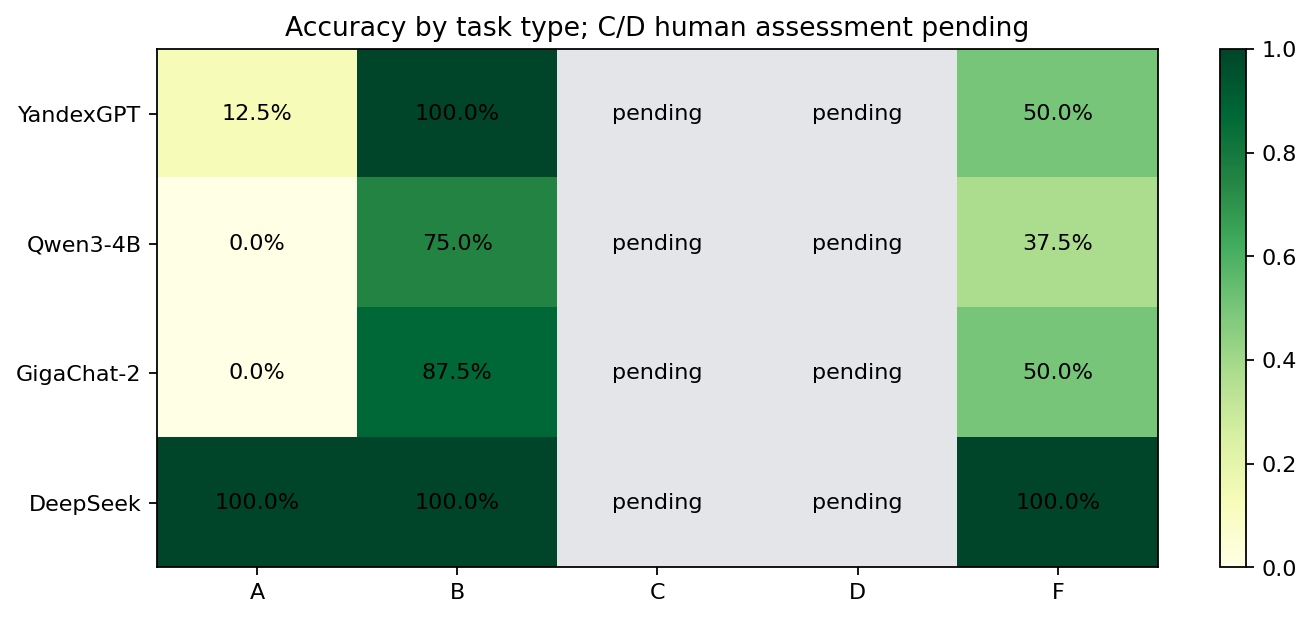

In [8]:
figure('heatmap.png')

**Что видно.** DeepSeek получил 8/8 на каждом из A, B и F. Yandex имеет 1/8 на A и 8/8 вердиктов B; Qwen — 0/8 и 6/8; Giga — 0/8 и 7/8. Значит, правильные концептуальные ответы не гарантируют столь же правильных расчётов. О непроверенных C/D по серым клеткам вывод не делается.

**Как читать точность с интервалами.** По горизонтали перечислены модели, по вертикали — доля верных ответов на 24 задачах A/B/F. Точка — наблюдаемая accuracy. Вертикальный отрезок — 95%-интервал, полученный повторной сборкой задач с возвращением (bootstrap). Чем длиннее отрезок, тем сильнее оценка меняется при таком пересборе.

**Зачем этот график.** Он напоминает, что 13/24 и 11/24 — оценки по небольшому набору, а не точные неизменные свойства моделей.

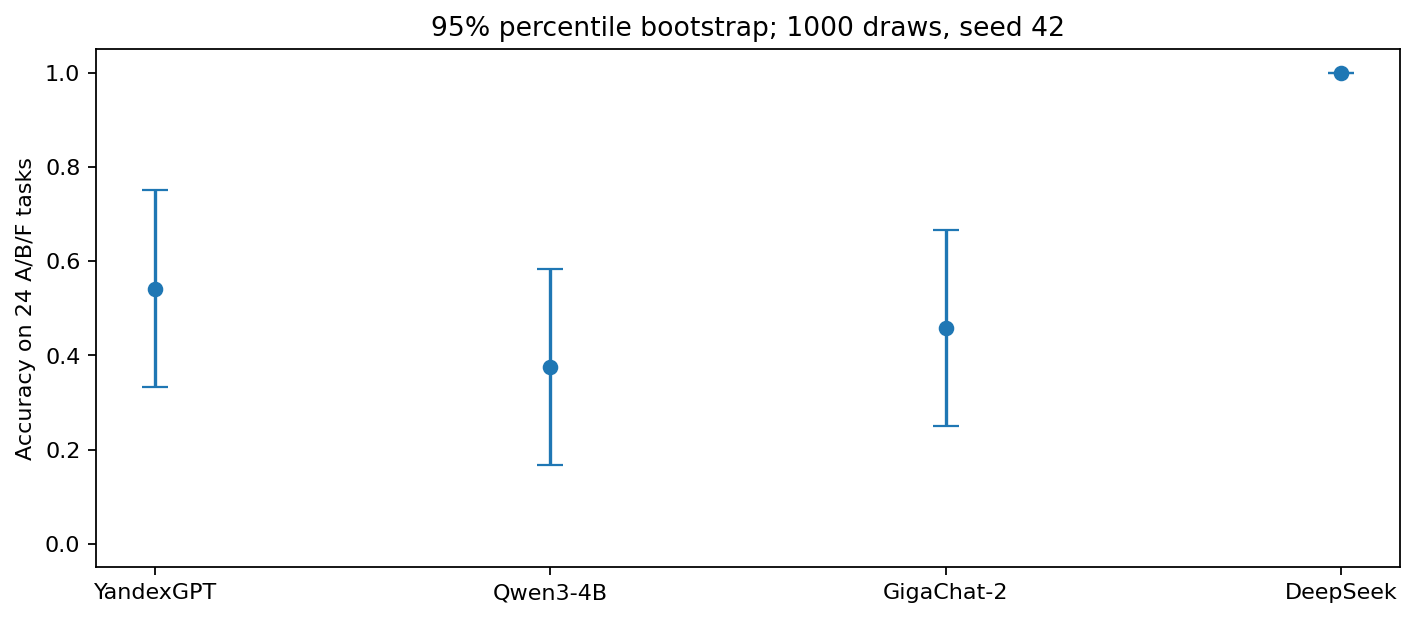

In [9]:
figure('accuracy_ci.png')

**Вывод с ограничением.** Point estimates: Yandex 54.2%, Qwen 37.5%, Giga 45.8%, DeepSeek 100%. У первых трёх интервалы широки. У DeepSeek отрезок вырождается в точку: если все наблюдения верны, bootstrap не может создать новую ошибку. Это не гарантия 100% на новых задачах. Значимость различий проверяется парным тестом в разделе 6, а не по одному визуальному пересечению интервалов.

**Следующая таблица уточняет причины неуспеха.** Она считает статусы формата по моделям: разрешённая Markdown-оболочка, повреждённый JSON или незавершённый ответ. Эти количества помогают понять, почему ответ не попал в число верных; содержание и интерфейсный формат не смешиваются.

In [10]:
table('format_status.csv')

,Модель,Статус ответа,Число случаев
0,YandexGPT,markdown_wrapper,236
1,YandexGPT,invalid_answer_type,101
2,YandexGPT,invalid_json,2
3,Qwen3-4B,none,238
4,Qwen3-4B,response_not_completed,1
5,Qwen3-4B,invalid_answer_type,98
6,Qwen3-4B,invalid_json,2
7,GigaChat-2,none,327
8,GigaChat-2,invalid_json,10
9,GigaChat-2,invalid_answer_type,2


model,status,n
YandexGPT,markdown_wrapper,236
YandexGPT,invalid_answer_type,101
YandexGPT,invalid_json,2
Qwen3-4B,none,238
Qwen3-4B,response_not_completed,1
Qwen3-4B,invalid_answer_type,98
Qwen3-4B,invalid_json,2
GigaChat-2,none,327
GigaChat-2,invalid_json,10
GigaChat-2,invalid_answer_type,2


**Итог блока.** На A/B/F DeepSeek получил 24/24, Yandex — 13/24, Giga — 11/24, Qwen — 9/24. Это результаты именно 24 автоматически проверяемых итоговых ответов. Они не включают самостоятельную оценку качества всех объяснений и не превращаются в итоговую оценку C/D.

Статус `markdown_wrapper` означает разрешённое снятие одной внешней Markdown-оболочки: содержание оценивается, нарушение чистого JSON отмечается отдельно. `invalid_json` означает, что такой нормализации недостаточно. `response_not_completed` — сервер не завершил ответ. Эти события требуют разных объяснений и не должны скрываться за одним словом «ошибка».

### Пересчитать точность и интервал на выбранном типе

Стандартный percentile bootstrap повторяет задачи с возвращением. При 8/8 все ресэмплы тоже дают 8/8; интервал [1,1] — вырожденность метода на этой малой выборке, а не гарантия отсутствия ошибок в будущем.

**Что делает пример с доверительным интервалом.** Мы выбираем одну модель и один тип задач. Компьютер 1000 раз собирает из наблюдавшихся ответов новый набор с возвращением: один ответ может попасть туда несколько раз, другой не попасть совсем. Каждый раз считается accuracy, после чего берутся границы распределения получившихся оценок. Это bootstrap — способ оценить чувствительность результата к составу небольшого набора.

Поменяв `CHOSEN_MODEL` или `CHOSEN_TYPE`, можно проверить другое число в общей таблице. Это всё ещё пересчёт прежних ответов, а не новая генерация.

In [11]:
scores=pd.read_csv(OUT/'automatic_scores.csv')
CHOSEN_MODEL='DeepSeek'; CHOSEN_TYPE='A'
values=scores.loc[(scores.model==CHOSEN_MODEL)&(scores.type==CHOSEN_TYPE),'correct'].astype(int).to_numpy()
print(accuracy_ci(values))
display(scores.loc[(scores.model==CHOSEN_MODEL)&(scores.type==CHOSEN_TYPE)])

{'accuracy': 1.0, 'ci_low': 1.0, 'ci_high': 1.0}


,model,task_id,type,correct,parsed,answer,confidence,format_error
72,DeepSeek,A01,A,True,True,0.3287671232876712,100.0,NaN
73,DeepSeek,A02,A,True,True,0.16333333333333333,100.0,NaN
74,DeepSeek,A03,A,True,True,0.7241379310344828,100.0,NaN
75,DeepSeek,A04,A,True,True,1.2,100.0,NaN
76,DeepSeek,A05,A,True,True,0.6456563062257954,100.0,NaN
77,DeepSeek,A06,A,True,True,1,100.0,NaN
78,DeepSeek,A07,A,True,True,0.2,100.0,NaN
79,DeepSeek,A08,A,True,True,0.875,100.0,NaN


**Почему у DeepSeek A интервал [1; 1].** В выбранном примере все восемь ответов правильны. Из восьми единиц невозможно выбрать bootstrap-набор с ошибкой, поэтому все повторные оценки равны 1. Это ограничение метода на таком маленьком наборе, а не доказательство «модель больше никогда не ошибётся».

Доверительный интервал здесь условен на нашем банке. Он не учитывает замену модели провайдером, новые темы задач и подбор других промптов. Для таких вопросов понадобятся дополнительные данные.

## 6 Статистическая значимость

На каждой паре моделей важны задачи, где правильность различается. Exact McNemar — двусторонний binomial test discordant ответов с p=0.5. Для четырёх моделей шесть сравнений; Holm контролирует множественность в этом семействе. Он не устраняет зависимость вариантов F или селекцию банка. Результаты относятся к этому набору задач и правилам формата.

**Зачем нужен статистический тест.** Наблюдаемая разница процентов может возникнуть случайно на маленьком наборе. Поскольку модели решали одни и те же задачи, мы сравниваем их попарно: считаем случаи, где права только первая модель, и случаи, где права только вторая. Exact McNemar проверяет, достаточно ли несимметричны эти два числа, чтобы различие нельзя было легко объяснить случайным направлением ошибок.

`p_exact` — результат отдельного теста. `p_holm` — значение после поправки на шесть одновременно рассмотренных пар. Поправка Holm снижает риск случайно выбрать «значимое» сравнение из нескольких.

In [12]:
from scipy.stats import binomtest
paired=read_json(OUT/'paired_comparisons.json');display(pd.DataFrame(paired))
row=next(r for r in paired if r['first']=='YandexGPT' and r['second']=='DeepSeek')
b,c=row['first_only_correct'],row['second_only_correct']
print('Discordant:',b,c,'exact p=',binomtest(b,b+c,.5).pvalue)
print('Учебный пример из методички: 3 против 0, p=',binomtest(3,3,.5).pvalue)

,first,second,first_only_correct,second_only_correct,p_exact,p_holm,significant_05
0,YandexGPT,Qwen3-4B,4,0,0.125000,0.375000,False
1,YandexGPT,GigaChat-2,2,0,0.500000,1.000000,False
2,YandexGPT,DeepSeek,0,11,0.000977,0.003906,True
3,Qwen3-4B,GigaChat-2,0,2,0.500000,1.000000,False
4,Qwen3-4B,DeepSeek,0,15,0.000061,0.000366,True
5,GigaChat-2,DeepSeek,0,13,0.000244,0.001221,True


Discordant: 0 11 exact p= 0.0009765625
Учебный пример из методички: 3 против 0, p= 0.25


**Какой вывод получен.** После поправки при уровне 0.05 DeepSeek отличается от каждой другой модели на A/B/F. Между Yandex, Qwen и Giga значимого различия не обнаружено. Это не означает, что они одинаковы: данных может быть мало. Учебный пример «3 задачи против 0» даёт p=0.25 — даже однонаправленная разница из трёх случаев недостаточна.

p-value — не вероятность того, что конкретная модель «хуже», и не размер эффекта. Это характеристика согласованности наблюдений с нулевой гипотезой теста. Зависимость вариантов F и особенности выбора банка всё равно ограничивают обобщение результата.

## 7 E как классификатор и роль отсутствующих ответов

Основные показатели F1 класса 1 и balanced accuracy. Дополнительно coverage и точность на ответившем подмножестве. Отсутствующее предсказание = -1, а не класс 0. Для F1 отказ на положительном объекте добавляет FN; отказ на отрицательном не добавляет FP. Поэтому F1 одного класса не симметрично штрафует все отказы; BA, confusion и coverage обязательны.

DeepSeek 20-shot: 35/100 допустимых ответов, все 35 правильны. Следовательно conditional accuracy=100%, но full accuracy=35%. Нельзя выбросить 65 незавершённых ответов и заявить качество 100% на исходном тесте. Giga zero-shot предсказывает класс 1 всем строкам: F1≈0.540, но BA=0.5, то есть разделения классов нет.

**Что такое задача E.** Здесь модель должна по шести числовым признакам выдать класс 0 или 1. `shots` означает, сколько размеченных примеров включили в текст вопроса: 0, 5 или 20. Проверяются одни и те же 100 тестовых объектов.

**Какие показатели читаем.** Precision — какая доля предсказаний «1» верна; recall — какую долю настоящих объектов класса 1 нашли. F1 объединяет precision и recall: высокий F1 требует разумного баланса. Balanced accuracy (BA) усредняет долю найденных объектов отдельно для класса 0 и класса 1. Coverage показывает, в скольких случаях модель вообще выдала допустимый класс. Все три аспекта нужны: модель может быть точной на части входов, но не давать ответа на остальные.

In [13]:
table('classification.csv')

,Модель,Примеров в запросе,F1 класса 1,Balanced accuracy,Точность на всех случаях,Доля допустимых ответов,Без допустимого класса
0,YandexGPT,0,0.000000,0.000000,0.00,0.00,100
1,YandexGPT,5,0.770833,0.825397,0.78,1.00,0
2,YandexGPT,20,0.901408,0.916559,0.93,1.00,0
3,Qwen3-4B,0,0.000000,0.015873,0.02,0.04,96
4,Qwen3-4B,5,0.850575,0.896825,0.87,1.00,0
5,Qwen3-4B,20,0.904110,0.922136,0.93,1.00,0
6,GigaChat-2,0,0.540146,0.500000,0.37,1.00,0
7,GigaChat-2,5,0.611570,0.626984,0.53,1.00,0
8,GigaChat-2,20,0.819277,0.864221,0.85,1.00,0
9,DeepSeek,0,0.806452,0.734663,0.75,0.76,24


model,shots,f1_minority,balanced_accuracy,accuracy,coverage,abstentions,explicit_refusals,incomplete,selective_accuracy,selective_f1,correct_positive,correct_negative
YandexGPT,0,0.000000,0.000000,0.00,0.00,100,100,0,NaN,NaN,0,0
YandexGPT,5,0.770833,0.825397,0.78,1.00,0,0,0,0.780000,0.770833,37,41
YandexGPT,20,0.901408,0.916559,0.93,1.00,0,0,0,0.930000,0.901408,32,61
Qwen3-4B,0,0.000000,0.015873,0.02,0.04,96,96,0,0.500000,0.000000,0,2
Qwen3-4B,5,0.850575,0.896825,0.87,1.00,0,0,0,0.870000,0.850575,37,50
Qwen3-4B,20,0.904110,0.922136,0.93,1.00,0,0,0,0.930000,0.904110,33,60
GigaChat-2,0,0.540146,0.500000,0.37,1.00,0,0,0,0.370000,0.540146,37,0
GigaChat-2,5,0.611570,0.626984,0.53,1.00,0,0,0,0.530000,0.611570,37,16
GigaChat-2,20,0.819277,0.864221,0.85,1.00,0,0,0,0.850000,0.819277,34,51
DeepSeek,0,0.806452,0.734663,0.75,0.76,24,0,24,0.986842,0.980392,25,50


**Как читать три панели классификации.** Горизонтальная ось `Shots` — число размеченных примеров в запросе. На первой панели показан F1 класса 1, на второй — balanced accuracy, на третьей — coverage (доля допустимых ответов). На всех трёх шкала от 0 до 1; больше обычно лучше. Сплошные линии — LLM, пунктирные ориентиры — LR и GaussianNB. У классических моделей нет точки при 0: zero-shot для них не измерялся.

**Зачем три панели рядом.** Один высокий показатель не должен скрывать, что часть объектов вообще осталась без ответа.

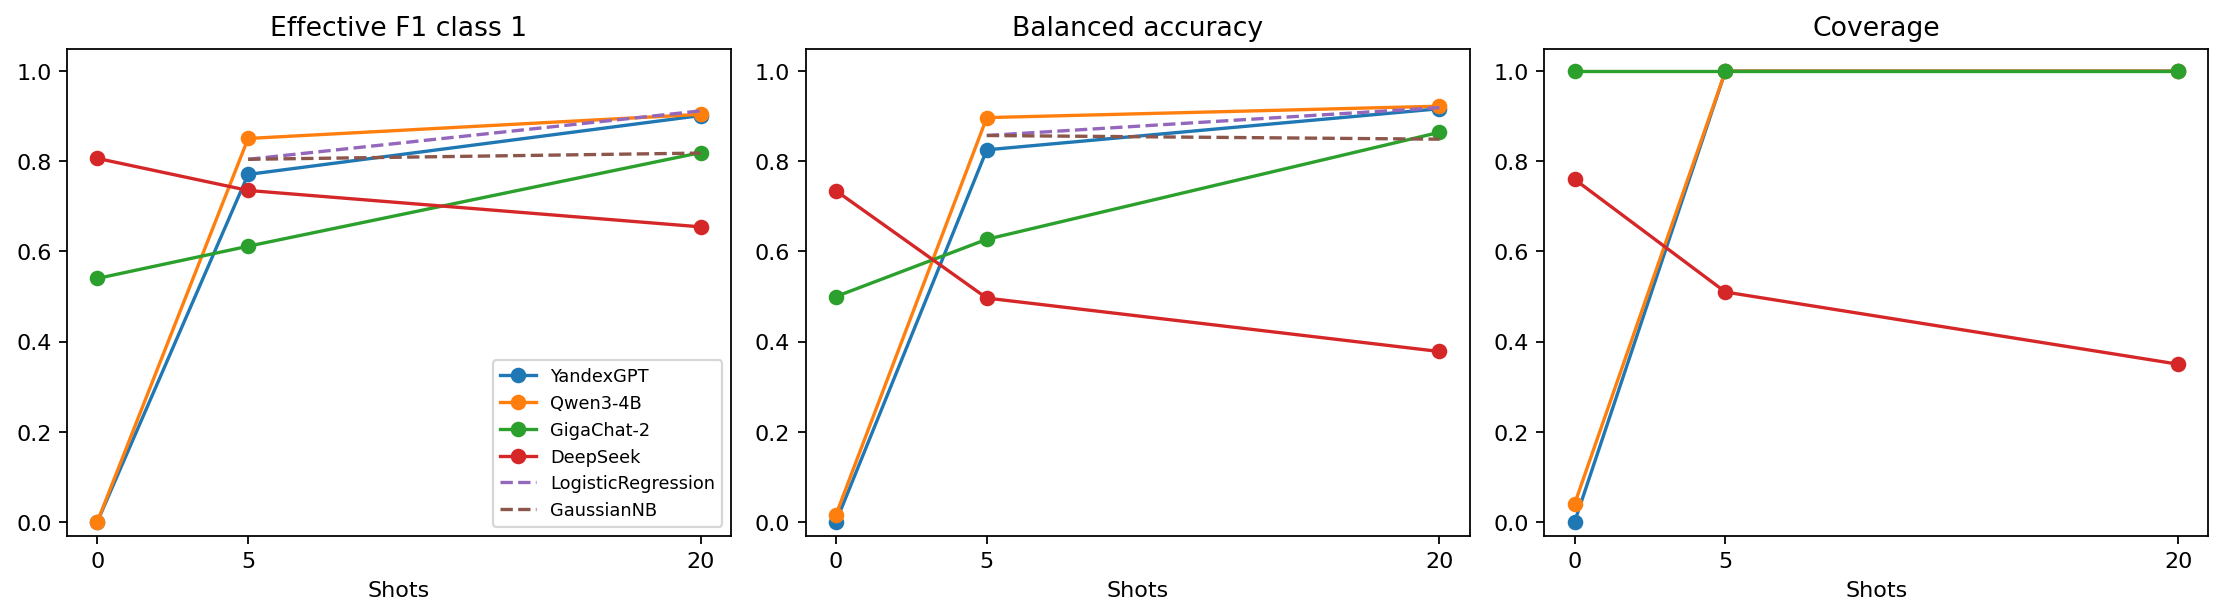

In [14]:
figure('classification.png')

**Что объясняет форму линий.** Qwen и Yandex заметно улучшают F1 с примерами, LR20 остаётся сильным ориентиром. У DeepSeek F1 снижается одновременно с coverage: 0.76 → 0.51 → 0.35. Это указывает на проблему завершения генерации в данном режиме, а не доказывает, что примеры испортили распознавание. Giga zero-shot имеет F1 около 0.54 при BA=0.5: она всем предсказала класс 1 и не разделила классы.

**Как читать график двух точностей.** В каждой панели одна модель. Сплошная линия показывает accuracy на всех 100 тестовых объектах. Пунктир — accuracy только среди объектов с допустимым ответом. Если эти линии расходятся, часть входов исключена из условной оценки. При полном отсутствии ответов условная точность не определена, поэтому соответствующая точка не рисуется.

**Зачем он нужен.** График демонстрирует, как можно получить впечатляющее качество, просто не учитывая пропуски.

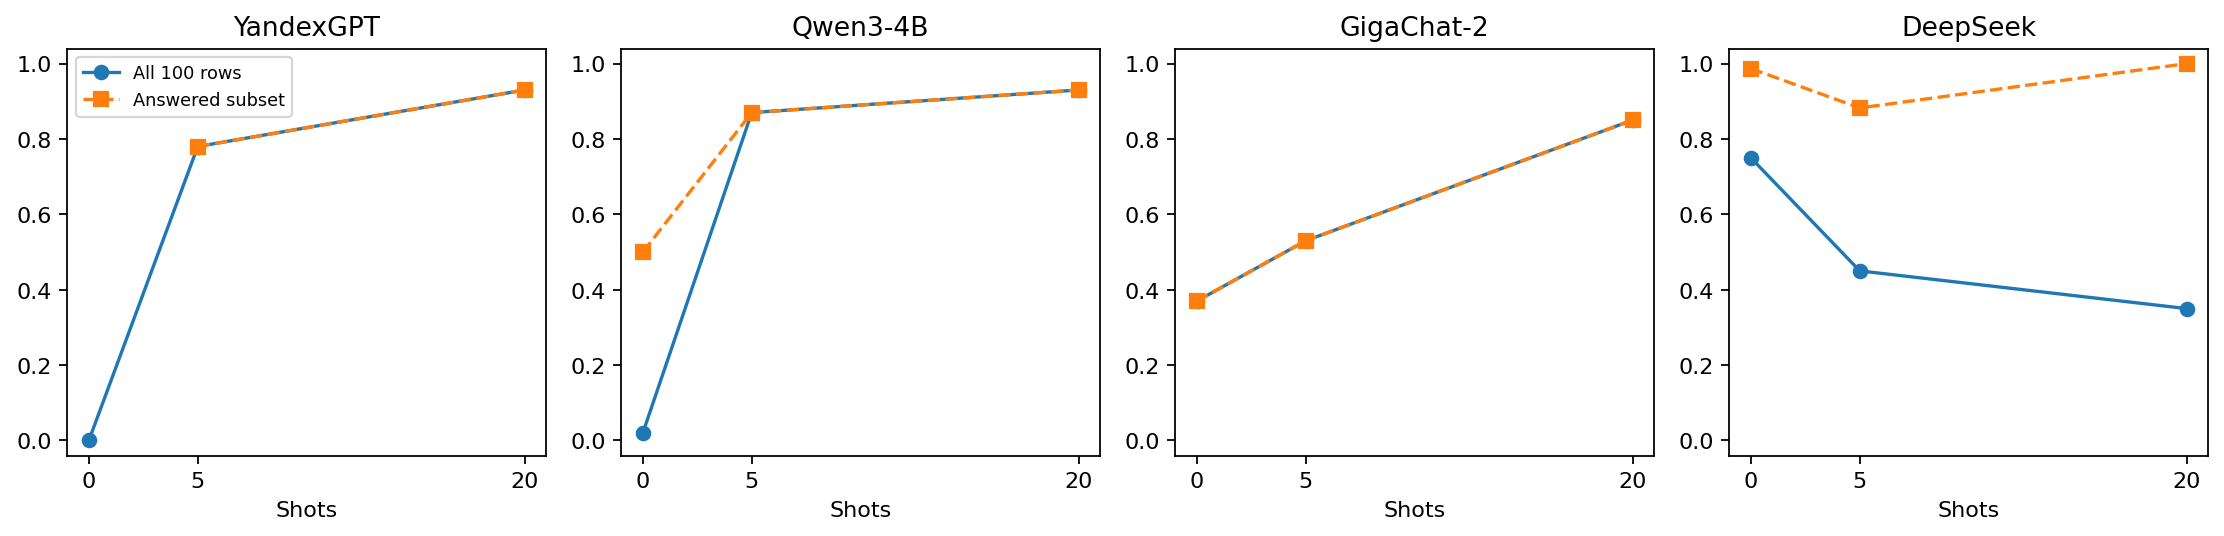

In [15]:
figure('selective_accuracy.png')

**Наглядный случай DeepSeek.** При 20 примерах пунктир равен 1, сплошная линия — 0.35. Это 35 правильных ответов из 35 полученных, но 65 объектов остались без класса. Фраза «точность 100%» без указания подмножества скрыла бы основную практическую проблему. Принимать условную точность за качество на исходных 100 объектах нельзя.

**Как читать матрицы для 20-shot.** Строки — настоящий класс 0 или 1. Столбцы — предсказание 0, предсказание 1 и отсутствие ответа. В каждой ячейке стоит число объектов; тёмная клетка содержит больше случаев. Правильные классы находятся в двух диагональных клетках первых двух столбцов. Верхняя клетка столбца Pred 1 — ложные тревоги, нижняя клетка Pred 0 — пропущенные положительные объекты. Третий столбец показывает отказы/незавершения отдельно.

**Почему добавлен третий столбец.** Обычная матрица 2×2 могла бы скрыть входы, которым класс вообще не назначен.

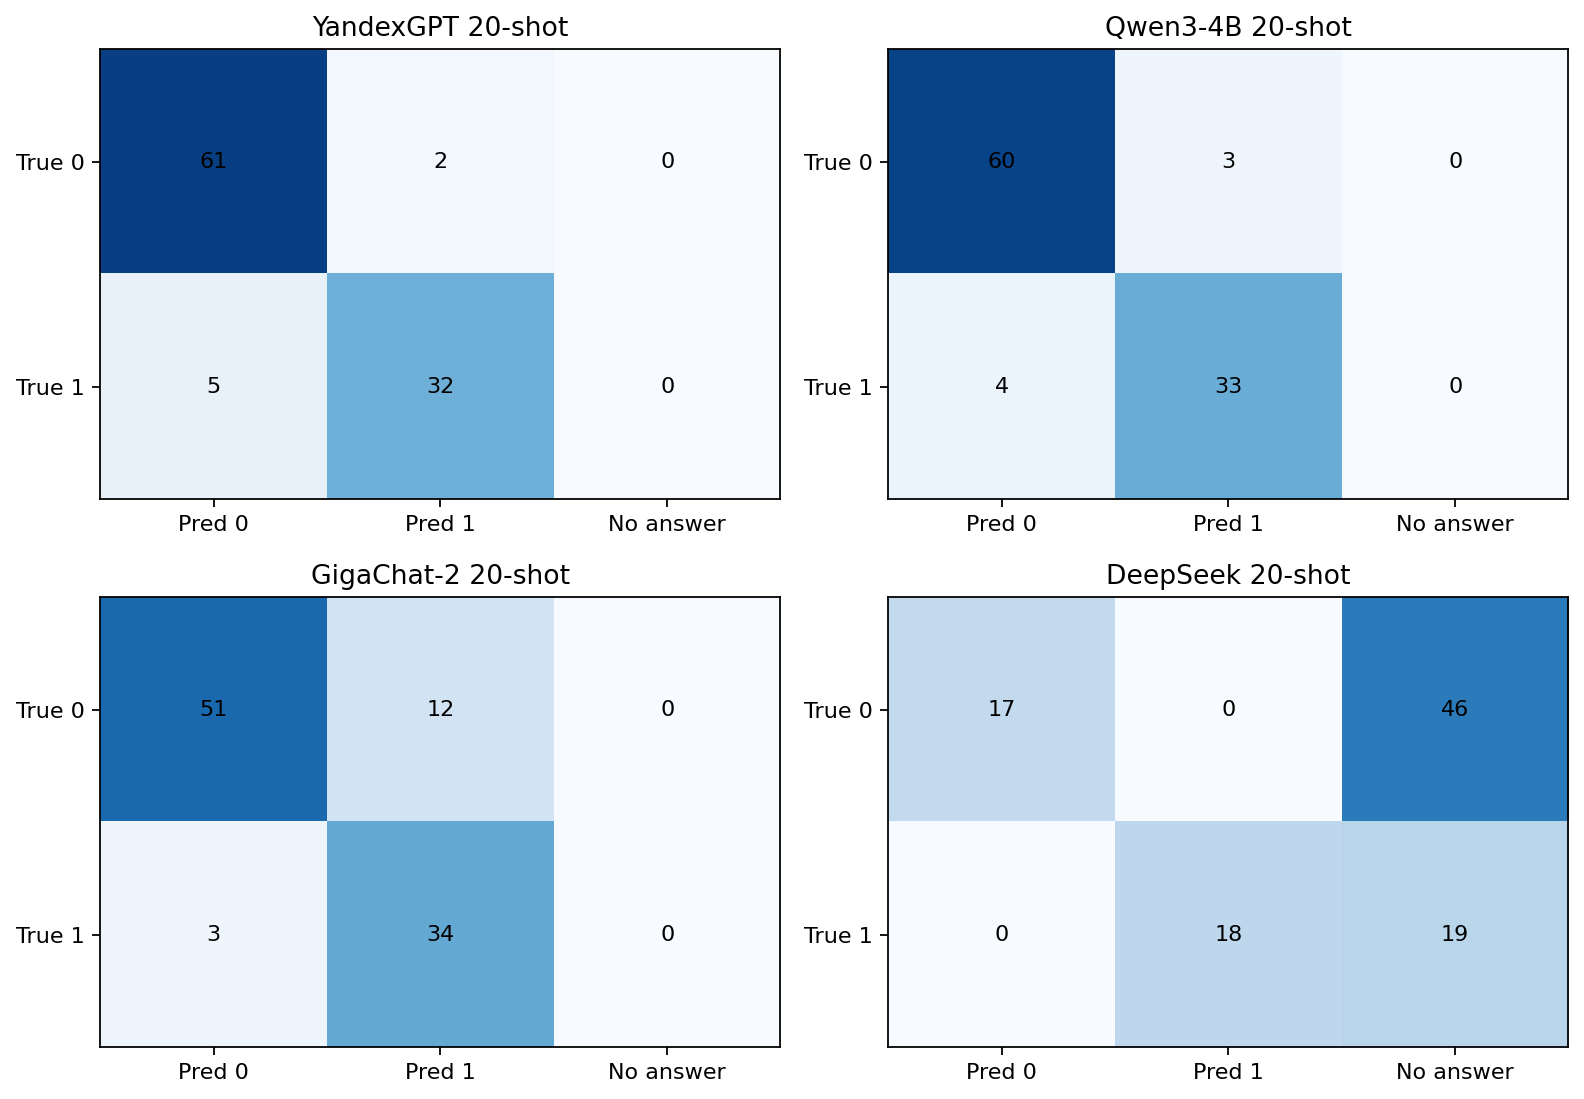

In [16]:
figure('confusion_20.png')

**Сравнение по объектам.** У Qwen 60 верных нулей и 33 верные единицы; ошибки — 3 ложные единицы и 4 пропущенные единицы. У DeepSeek 17 верных нулей и 18 верных единиц, неверных классов нет, зато нет ответа для 46 нулей и 19 единиц. Последний столбец объясняет падение полного качества без необходимости угадывать причины по одному среднему.

**Главный результат классификации.** Qwen при 5 примерах имеет F1 ≈ 0.851, при 20 — 0.904. LR соответственно ≈ 0.804 и 0.912. Значит, простая классическая модель остаётся серьёзным конкурентом. У DeepSeek F1 падает при росте shots, но одновременно падает покрытие: 76% → 51% → 35%. Поэтому по одному F1 нельзя заключить, что дополнительные примеры ухудшили именно способность распознавать класс.

`selective_accuracy` считается только среди допустимых ответов, а обычная `accuracy` — на всех 100 строках. Сравнивать их без указания знаменателя нельзя. `explicit_refusals` — явные ответы «недостаточно данных», `incomplete` — незавершённые генерации; это разные причины отсутствия класса.

**Что делает контрольный расчёт по DeepSeek.** Он берёт все 100 предсказаний 20-shot, сначала считает долю верных на полном тесте, затем отдельно — на строках с допустимым ответом. Значение -1 обозначает отсутствие класса и никогда не заменяется нулём. Матрица в конце сохраняет третий столбец «нет ответа».

**Зачем пересчитывать явно.** Это короткая проверка самого необычного результата: «100% среди отвеченных» и «35% на всех входах» одновременно могут быть верны.

In [17]:
pred=pd.read_csv(OUT/'predictions.csv')
subset=pred[(pred.model=='DeepSeek')&(pred.shots==20)]
assert len(subset)==100
print('Full accuracy:',np.mean(subset.prediction==subset.truth))
answered=subset[subset.prediction!=-1]
print('Coverage:',len(answered)/100,'selective accuracy:',np.mean(answered.prediction==answered.truth))
print('Confusion rows true 0/1; columns predicted 0/1/no answer:')
print(confusion(subset.truth.to_numpy(),subset.prediction.to_numpy()))

Full accuracy: 0.35
Coverage: 0.35 selective accuracy: 1.0
Confusion rows true 0/1; columns predicted 0/1/no answer:
[[17, 0, 46], [0, 18, 19]]


**Разбор по количествам.** DeepSeek выдал 35 классов: 18 правильных единиц и 17 правильных нулей. Ещё 65 случаев не завершились. Поэтому 35/35 = 100% на отвеченном подмножестве, но 35/100 = 35% на исходной задаче. Подмножество выбрано поведением процесса генерации, а не независимым случайным отбором.

Из этих данных нельзя обещать 100% для произвольного нового объекта. Если системе нужен класс для каждого входа, 65 пропусков — существенная проблема даже при безошибочности оставшихся ответов.

## 8 H5 H10 H12

Прогноз команды — confirm для каждой гипотезы; правила сохранены до основных запусков каждой модели. Основная H5 заранее выбрана как Yandex vs Qwen, не заменяется более выгодным DeepSeek. H10: signed confidence gap, 95% кластерный bootstrap с сохранением F-пар. H12: при 5 примерах не меньшее качество LR с margin 0.05 F1; при 20 — проигрыш LR. Границы H12 односторонние 95% (перцентили 5/95), это не тот же интервал, что двухсторонний 95% 2.5/97.5.

Гипотеза H12 — сочетание двух утверждений: обе части подтверждены → confirm; хотя бы одна опровергнута → reject; иначе insufficient_data. Отсутствие значимости не доказывает равенство.

**Что проверяют гипотезы.** Мы не просто искали интересные различия, а заранее записали три ожидания. H5 спрашивает, сильнее ли маленькая Qwen отстаёт от выбранной крупной Yandex в расчётах, чем в концептуальных вопросах. H10 спрашивает, превышает ли самооценка уверенности фактическую правильность. H12 спрашивает, конкурентна ли LLM с LR при 5 примерах, но уступает ли ей при 20.

В объекте ниже `confirm` значит «зарегистрированный критерий выполнен», `reject` — «данные противоречат ему», `insufficient_data` — «заданный критерий не позволяет сделать определённый вывод». Последний статус не равен доказательству равенства моделей. Далее каждая картинка раскрывает отдельную гипотезу.

In [18]:
hyp=read_json(OUT/'hypotheses.json')
readable_hypotheses(hyp)

,Гипотеза,Модель / пара,Результат
0,H5: отставание в расчётах относительно концепций,Yandex–Qwen,Данных для определённого вывода недостаточно
1,H10: завышение уверенности,YandexGPT,Критерий подтверждения выполнен
2,H10: завышение уверенности,Qwen3-4B,Критерий подтверждения выполнен
3,H10: завышение уверенности,GigaChat-2,Критерий подтверждения выполнен
4,H10: завышение уверенности,DeepSeek,Гипотеза противоречит данным
5,"H12: не хуже LR при 5, хуже при 20",YandexGPT,Данных для определённого вывода недостаточно
6,"H12: не хуже LR при 5, хуже при 20",Qwen3-4B,Данных для определённого вывода недостаточно
7,"H12: не хуже LR при 5, хуже при 20",GigaChat-2,Гипотеза противоречит данным
8,"H12: не хуже LR при 5, хуже при 20",DeepSeek,Данных для определённого вывода недостаточно


**Как читать H5.** Здесь одна точка, потому что проверяется одна заранее выбранная пара Yandex–Qwen. Вертикальная ось — не accuracy, а разность двух отставаний: `(Yandex−Qwen на A) − (Yandex−Qwen на B)`. Положительное значение поддерживало бы ожидание «маленькая модель сильнее отстаёт в расчётах». Отрезок — 95%-интервал, горизонтальная линия — нулевое различие.

**Почему не сравниваем просто два общих процента.** H5 говорит о сравнении разрывов между типами задач, а не об общей победе крупной модели.

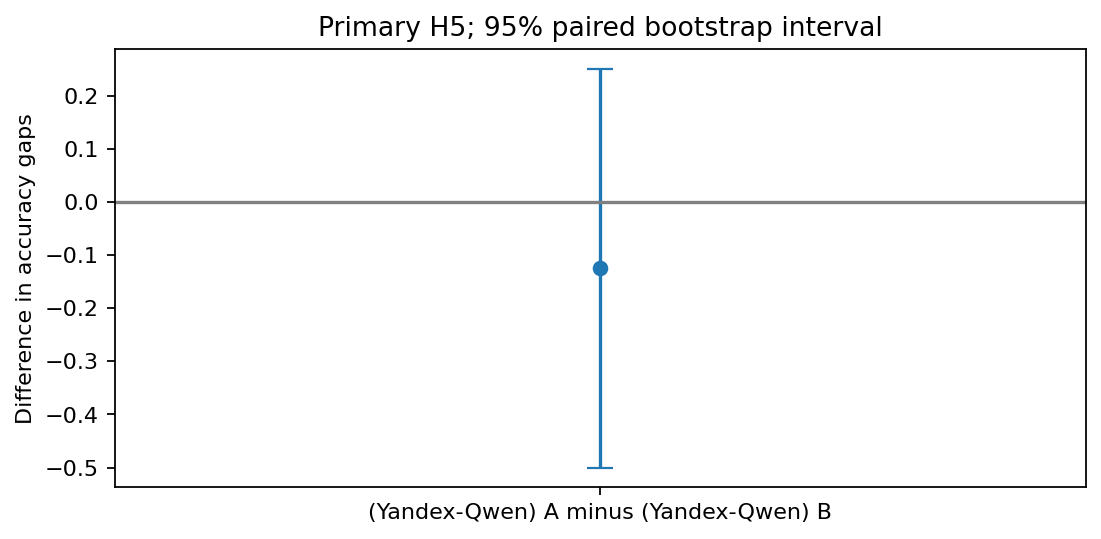

In [19]:
figure('h5_gap.png')

**Что получилось.** На A разрыв 0.125, на B — 0.25; итог -0.125, интервал [-0.5; 0.25]. Ноль входит в интервал, поэтому данных недостаточно для зарегистрированного решения. Отрицательная точка сама по себе ещё не доказывает обратную закономерность. Замена Yandex на более успешную DeepSeek после результатов изменила бы исходную гипотезу.

**Как читать разницу уверенности и правильности.** По горизонтали — модель. По вертикали — средняя заявленная уверенность минус фактическая accuracy на ответах с доступной confidence. Ноль означает совпадение в среднем; положительное значение — переуверенность. Например, +0.40 означает разницу 40 процентных пунктов. Отрезки — 95%-интервалы с сохранением связанных задач F в одном кластере.

**Зачем этот график.** Слова «уверен на 100%» проверяются по фактическим ошибкам, а не принимаются на веру.

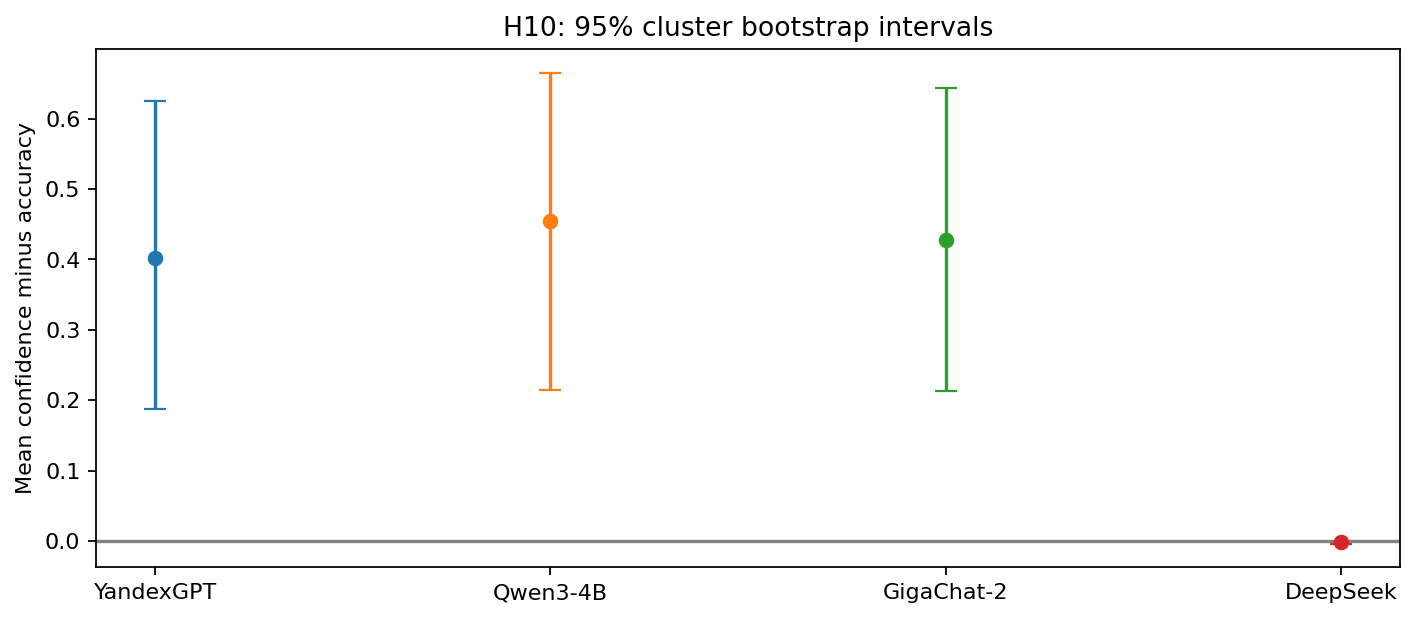

In [20]:
figure('h10_gap.png')

**Наблюдаемый результат.** У Yandex разрыв около +40.2 п.п., Qwen +45.5 п.п., Giga +42.7 п.п.; их интервалы выше нуля. У DeepSeek разрыв около -0.21 п.п. на 24/24 верных ответах. Это опровергает гипотезу завышения на данном наборе для DeepSeek, но не доказывает универсальную калибровку: почти все его confidence находятся около 100%.

**Как читать диаграммы надёжности.** В каждой панели горизонтальная координата — средняя confidence в группе похожих уверенностей, вертикальная — доля верных ответов в этой группе. Пунктирная диагональ означает идеальное совпадение: например, среди ответов с уверенностью 80% верны примерно 80%. Точка ниже диагонали означает переуверенность, выше — недоуверенность. Размер точки зависит от числа ответов в группе.

**Зачем нужна эта картинка помимо средней разницы.** Она показывает, в каких диапазонах уверенности возникает несоответствие.

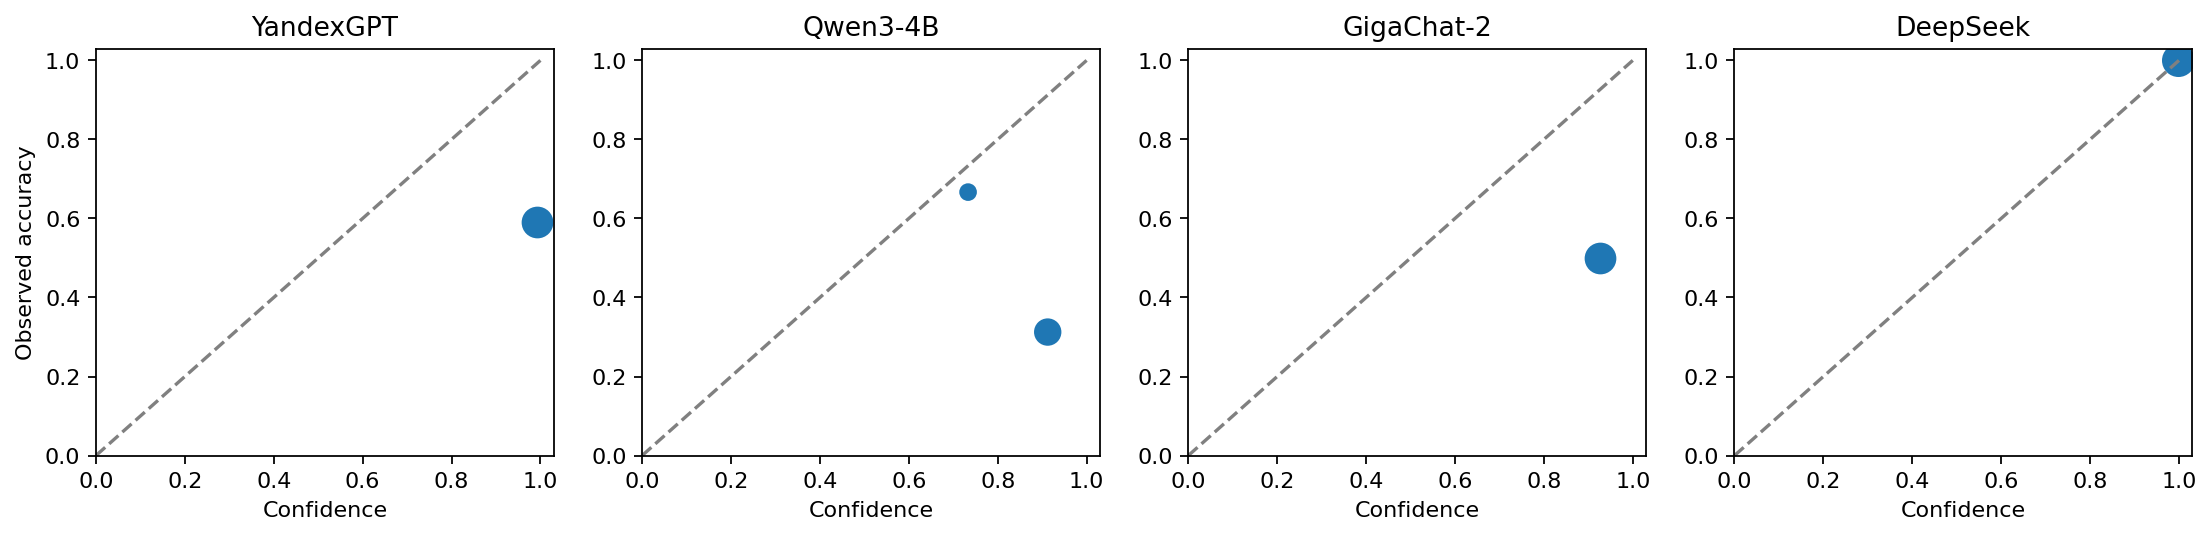

In [21]:
figure('reliability.png')

**Какой вывод допустим.** У трёх моделей точки заметно ниже диагонали, поэтому высокая confidence не защищает от ошибок. У DeepSeek точка близка к правому верхнему углу. Но небольшой банк и концентрация почти всех ответов в одном высоком диапазоне не позволяют судить о поведении при confidence 20% или 50%. Низкая ECE не обязательно означает, что confidence умеет выделять рискованные случаи.

**Как читать сравнение с LR.** Левая панель относится к пяти примерам, правая — к двадцати. Вертикальная ось — `F1 LLM − F1 LR`: выше нуля LLM лучше по наблюдаемому F1, ниже — хуже. Серая линия — равенство. Красная пунктирная линия -0.05 — заранее допустимое отставание для «не хуже» при 5-shot.

У каждого отрезка показаны нижняя и верхняя односторонние 95%-границы. При 5-shot нижняя граница должна быть выше красной линии. При 20-shot верхняя должна быть ниже нуля, чтобы поддержать ожидаемый проигрыш. Это не обычные двусторонние 95%-интервалы.

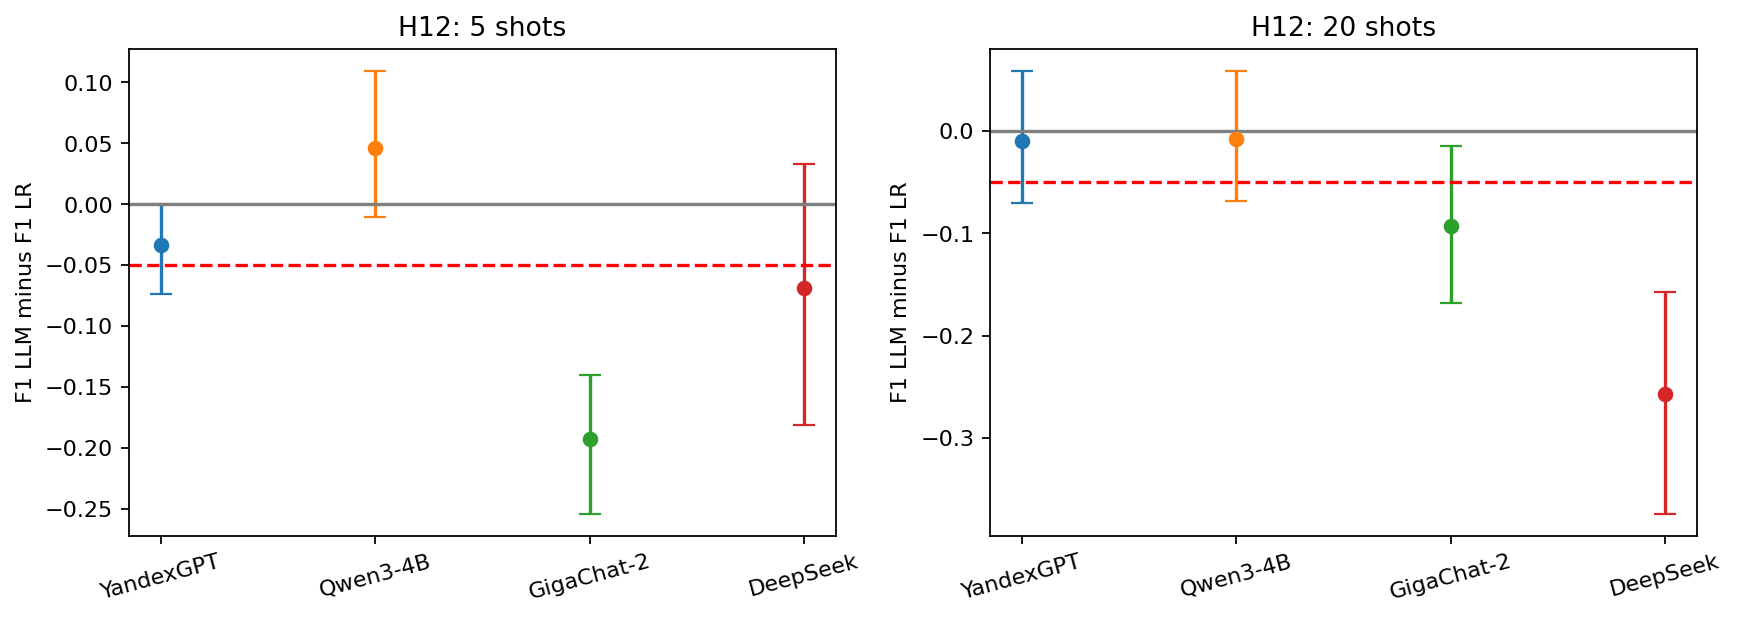

In [22]:
figure('h12_delta.png')

**Что говорят интервалы.** Qwen проходит критерий «не хуже» при пяти примерах, но её проигрыш при двадцати не установлен. У Giga интервал 5-shot целиком ниже -0.05, то есть первая часть гипотезы опровергнута; проигрыш в 20-shot поддержан. У DeepSeek 20-shot эффективное качество ниже LR, но часть 5-shot остаётся неопределённой. Поэтому нельзя заменить два условия одной фразой «LLM хуже/лучше LR».

**Итог по гипотезам простыми словами.** H5 не получила определённого ответа: интервал разности разрывов пересекает ноль. H10 подтверждена для Yandex, Qwen и Giga, но не для DeepSeek на выбранных 24 задачах. H12 опровергнута у Giga; у остальных моделей полный составной тезис остался неопределённым.

Это не «неудачная лабораторная»: честная проверка может не подтвердить прогноз. Нельзя менять пару H5 или допустимое отставание H12 после просмотра таблиц, чтобы получить желаемый статус.

**Что делает повторный расчёт H12.** Для выбранных модели и shots сравнивается F1 LLM с F1 логистической регрессии на тех же тестовых строках. При bootstrap индексы строк выбираются одинаково для обеих моделей — так сохраняется парность сравнения. `delta` означает F1 LLM минус F1 LR.

Для 5 примеров «не хуже» заранее означает отставать не более чем на 0.05 F1. Это пять сотых шкалы F1, а не 5% относительной ошибки. Отсутствие значимого различия само по себе не доказывает такое не меньшее качество.

In [23]:
MODEL='GigaChat-2'; SHOTS=5
subset=pred[(pred.model==MODEL)&(pred.shots==SHOTS)].set_index('row_id').loc[ids]
print(h12_comparison(y,subset.prediction.to_numpy(),baseline_predictions['LogisticRegression',SHOTS],SHOTS))
print(inspect.getsource(h12_comparison))

{'shots': 5, 'delta_f1_llm_minus_lr': -0.19277757815307228, 'one_sided_95_lower': -0.25363048334358507, 'one_sided_95_upper': -0.13967070043426183, 'decision': 'reject'}
def h12_comparison(y, p, baseline, shots):
    indices = np.random.default_rng(SEED).integers(0, len(y), size=(N_BOOT, len(y)))
    draws = [classification_metrics(y[i], p[i])["f1_minority"]-classification_metrics(y[i], baseline[i])["f1_minority"] for i in indices]
    low, high = map(float, np.quantile(draws, [.05, .95]))
    delta = classification_metrics(y, p)["f1_minority"]-classification_metrics(y, baseline)["f1_minority"]
    if shots == 5:
        decision = "confirm" if low > -.05 else "reject" if high < -.05 else "insufficient_data"
    else:
        decision = "confirm" if high < 0 else "reject" if low >= 0 else "insufficient_data"
    return {"shots": shots, "delta_f1_llm_minus_lr": delta, "one_sided_95_lower": low,
            "one_sided_95_upper": high, "decision": decision}



**Почему выбранный пример Giga 5-shot даёт reject.** F1 Giga ≈ 0.6116, LR ≈ 0.8043; разность около -0.1928. Даже верхняя односторонняя 95%-граница около -0.1397 ниже допустимых -0.05. Значит, первая часть гипотезы «не хуже при пяти примерах» противоречит данным.

Исходный код функции выводится для проверки зарегистрированных правил. Перцентили 5/95 дают показанные односторонние 95%-границы; это не обычный двусторонний 95%-интервал с перцентилями 2.5/97.5.

## 9 D запуск и методологическая корректность

Читайте три столбца отдельно: завершился ли процесс, напечатан ли JSON, совпали ли численные метрики. Qwen D07 — словарь без print, процесс завершается успешно, задача не выполнена. Giga D01 диагностически печатает accuracy под именем balanced_accuracy; численная близость не исправляет неверную метрику.

В Giga все первичные ответы D имеют недопустимый JSON, поэтому основной end-to-end pass=0. После этого выполнена отдельная диагностика точных фрагментов кода (6/8 запустились), не меняющая первичные оценки. Она явно вторична. DeepSeek 8/8 запусков и метрик не заменяет двух независимых проверок методологии.

**Что оценивается у кода.** Просьба «напиши программу» имеет несколько уровней успеха. Нужно получить код в нужном формате, запустить его без исправлений, прочитать требуемый вывод и проверить, правильно ли решена ML-задача. Эти уровни представлены разными столбцами: `pass_at_1`, `output_is_json`, `metrics_match_reference`.

Вторая таблица — отдельная диагностика Giga. Она показывает исполнение точных фрагментов кода, которые присутствовали вне допустимого первичного ответа. Это полезно для понимания ошибок, но не повышает исходные баллы.

In [24]:
table('code_metrics.csv')

,Модель,Задача,Первый запуск / контракт выполнен,Вывод является JSON,Числа совпали с эталоном,Код завершения процесса
0,YandexGPT,D01,True,False,True,0.0
1,YandexGPT,D02,False,False,False,1.0
2,YandexGPT,D03,True,True,True,0.0
3,YandexGPT,D04,True,True,True,0.0
4,YandexGPT,D05,True,True,True,0.0
5,YandexGPT,D06,False,False,False,1.0
6,YandexGPT,D07,True,True,True,0.0
7,YandexGPT,D08,True,True,True,0.0
8,Qwen3-4B,D01,False,False,False,1.0
9,Qwen3-4B,D02,True,True,True,0.0


model,task_id,pass_at_1,output_is_json,metrics_match_reference,exit_code
YandexGPT,D01,True,False,True,0.0
YandexGPT,D02,False,False,False,1.0
YandexGPT,D03,True,True,True,0.0
YandexGPT,D04,True,True,True,0.0
YandexGPT,D05,True,True,True,0.0
YandexGPT,D06,False,False,False,1.0
YandexGPT,D07,True,True,True,0.0
YandexGPT,D08,True,True,True,0.0
Qwen3-4B,D01,False,False,False,1.0
Qwen3-4B,D02,True,True,True,0.0


**Как читать столбцы исполнения кода.** По горизонтали — модели, по вертикали — доля из восьми заданий D. В каждой группе три критерия: завершение процесса/первичного контракта, корректный JSON в stdout и совпадение численных метрик с эталоном. Все столбцы отвечают на разные вопросы; высокий первый не делает остальные автоматически высокими.

Диагностически извлечённый код Giga не включён в этот основной график, потому что его первичный формат был неверен.

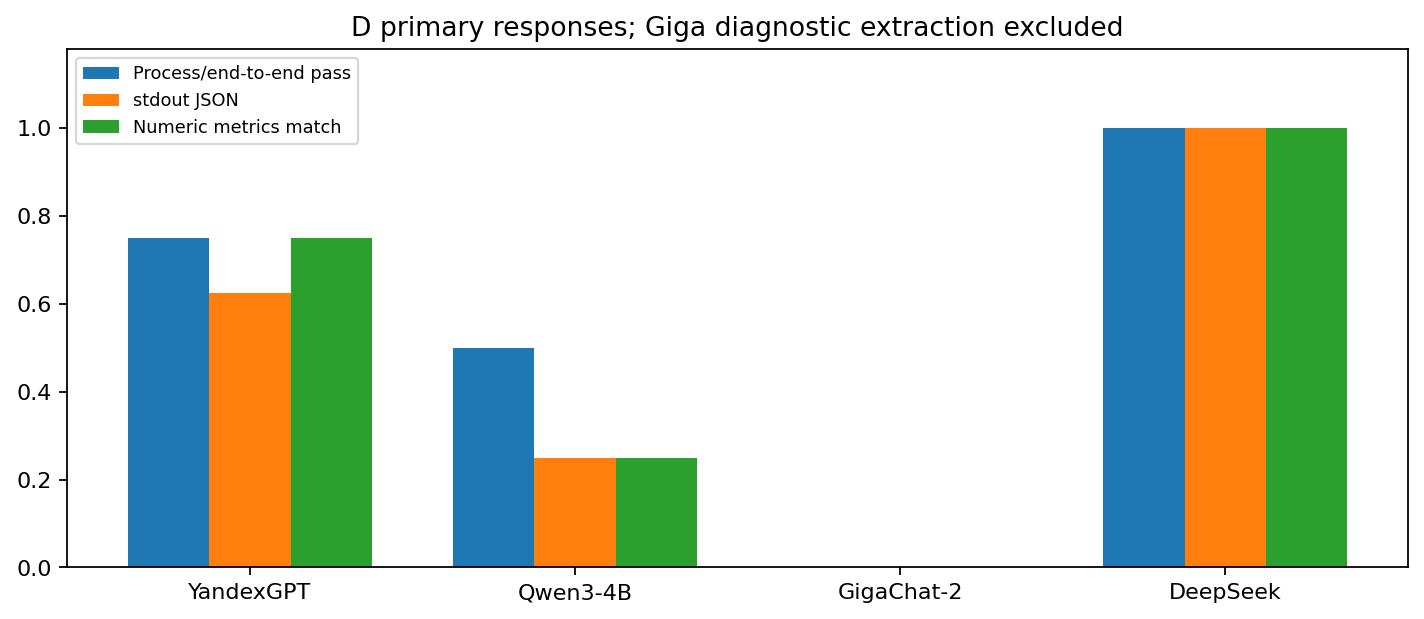

In [25]:
figure('code_execution.png')

**Почему ступени важны.** У Qwen процесс завершился без ошибки в 4 случаях, но нужный JSON и метрики получены лишь в 2. У Yandex 6 успешных процессов, 5 JSON-выводов и 6 численных совпадений: числа иногда можно диагностически извлечь из Python dict, хотя это не JSON. DeepSeek имеет 8/8 по трём техническим критериям. Проверка утечки и правильности методики всё равно остаётся отдельной.

**Далее — отдельная диагностика кода Giga.** Читаются прежние результаты запуска извлечённых фрагментов, а не запускается новый код. Эта таблица помогает отличить ошибку оформления ответа от runtime-ошибки программы и не изменяет первичную оценку 0/8.

In [26]:
display(pd.DataFrame(read_json(ROOT/'analysis/gigachat/diagnostic_code_execution.json'))[['task_id','runs_without_error','output_is_json','metrics_match_reference','inspection_note']])

,task_id,runs_without_error,output_is_json,metrics_match_reference,inspection_note
0,D01,True,False,True,Inspected numpy/sklearn only. Uses estimator.s...
1,D02,False,False,False,Inspected sklearn/numpy only; Pipeline used wi...
2,D03,True,False,True,Inspected sklearn only; train-only CV and test...
3,D04,True,True,False,Inspected sklearn only; output key balance_acc...
4,D05,False,False,False,Inspected sklearn/json references only; Pipeli...
5,D06,True,True,True,Inspected sklearn/json only; body of invalid t...
6,D07,True,False,True,Inspected sklearn only; descriptive clustering...
7,D08,True,True,True,Inspected sklearn only; correct original class...


**Что видно на примерах.** DeepSeek дал 8/8 успешных программ и совпадений численных метрик. Qwen имеет 4/8 завершившихся процессов, но лишь 2/8 JSON-выводов и совпадений метрик: выражение без print тоже может завершиться с кодом 0. У Giga первичный формат нарушен во всех восьми случаях; из извлечённых для отдельной диагностики фрагментов запустились 6/8.

Численное совпадение ещё не доказывает правильную методологию. В Giga D01 фактически вычислена accuracy, названная balanced_accuracy; на этом наборе числа оказались близки. Поэтому «не упало» и «правильно выполнено» обязательно проверяются отдельно.

**Что делает ячейка с сохранённой программой.** Она показывает исходную строку answer и ранее записанные файлы .py, stdout и stderr выбранной задачи. Сейчас ничего из этого кода не исполняется. По умолчанию выбран DeepSeek D01: поиск параметра C для SVM внутри обучающей выборки.

stdout — то, что программа напечатала; stderr — сообщения об ошибках. По ним можно проверить, что таблица исполнения имеет конкретный источник, а не была заполнена вручную.

In [27]:
MODEL='DeepSeek'; TASK='D01'
folder,analysis,_,_=MODELS[MODEL]
rs=read_lines(ROOT/'results/models'/folder/'responses.jsonl')
r=next(r for r in rs if r['stage']=='main' and r['task_id']==TASK)
print('Original answer string:');print(r['parsed']['answer'] if r['parsed'] else raw_text(r))
for suffix in ['py','stdout.txt','stderr.txt']:
    p=ROOT/'analysis'/analysis/'code_execution'/(TASK+'.'+suffix)
    if p.exists():print('\nSAVED '+suffix+'\n'+p.read_text(encoding='utf-8'))
print('Эта ячейка только читает сохранённый код и вывод, ничего не исполняет.')

Original answer string:
import json
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import balanced_accuracy_score

X, y = load_breast_cancer(return_X_y=True)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('svc', SVC(kernel='rbf', gamma='scale'))
])

param_grid = {'svc__C': [0.1, 1, 10]}
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

grid = GridSearchCV(
    pipe,
    param_grid=param_grid,
    scoring='balanced_accuracy',
    cv=cv,
    n_jobs=1
)

grid.fit(X_train, y_train)
best_C = grid.best_params_['svc__C']
y_pred = grid.predict(X_test)
test_ba = balanced_accuracy_score(y_test, y_pred)

print(json.dumps({'best_C': best_C, 'balanc

**На что обратить внимание в D01.** Данные сначала разделены на train/test. Масштабирование и SVM объединены в Pipeline, а C выбирается с кросс-валидацией только на train. Test используется для итоговой оценки. Если бы scaler или поиск параметров использовал test, оценка перестала бы быть независимой.

Пустой stderr в одиночку не означает качественного решения: некоторые неверные программы вообще ничего не выводят. Здесь его нужно читать вместе со stdout, кодом и условиями задания.

## 10 Разбор конкретных ошибок

Пять содержательных/форматных примеров и один незавершённый запрос DeepSeek. Данные ниже дословно взяты из журналов. Объяснения механизмов и границ интерпретации подробно разобраны в личном отчёте, раздел «Разбор ошибок».

Yandex A03: рассуждение получает 0.7241 и затем ошибочно заменяет результат на 0.6364. Qwen A06: признаёт два голоса за 1, но отвечает 0. Qwen B03: отсутствие меток ошибочно считает отсутствием утечки. Giga B05: путает рост штрафа C с усилением регуляризации. F05: JSON-дробь 2/3 не является числом JSON. DeepSeek E: reasoning_tokens=4096 исчерпывают бюджет до итогового класса.

**Зачем разбирать ошибки после таблиц.** Средний процент говорит, сколько было неуспехов, но не объясняет, какого они рода. Ниже сохранены точные исходные примеры: ошибочный итог при правильной формуле, неверное голосование соседей, неправильное понимание утечки, путаница с регуляризацией, ошибка JSON и исчерпание лимита рассуждений.

`reference` — эталон, `parsed` — прочитанный ответ, `raw_text` — исходный текст. Мы не исправляем ответ перед сравнением.

In [28]:
readable_cases(read_json(OUT/'case_studies.json'))

,Модель,Задача,Эталон,Ответ,Что зафиксировано
0,YandexGPT,A03,0.724138,0.6363636363636364,"Формат читается, итоговый ответ неверен (есть ..."
1,Qwen3-4B,A06,1,0,"Формат читается, итоговый ответ неверен"
2,Qwen3-4B,B03,False,True,"Формат читается, итоговый ответ неверен"
3,GigaChat-2,B05,True,False,"Формат читается, итоговый ответ неверен"
4,YandexGPT,F05,0.666667,Нет допустимого итогового ответа,invalid_json
5,DeepSeek,E01,Класс строки из теста,Нет допустимого итогового ответа,incomplete


**Что эти примеры позволяют обосновать.** У Yandex A03 ошибка видна в переходе от 0.7241 к 0.6364; у Qwen A06 вывод противоречит указанным двум голосам за класс 1. У Qwen B03 концептуально неверно отрицание утечки через статистики test. У Giga B05 перепутана сила регуляризации. В F05 математически понятное `2/3` не является числом JSON. DeepSeek E01 не успел выдать класс, потратив 4096 токенов на рассуждения.

Мы видим место ошибки в ответе и её практическое следствие, но не внутренний механизм нейросети. Поэтому нельзя уверенно приписывать ошибку «лень модели» или доказанное запоминание без отдельного эксперимента.

## 11 Скорость стоимость память

Рубли за верный ответ рассчитаны **на A/B/F**, с тем же знаменателем, что и accuracy. Цена всех 344 вызовов — другой показатель. Тарифная цена, списание денег и резерв неизвестных сетевых попыток различаются. У Qwen API-цена 0, полная стоимость электричества/оборудования неизвестна.

У Giga prompt_tokens не включает бесплатный кэш: полный объём больше тарифицируемого. У DeepSeek reasoning уже включён в output_tokens; повторно прибавлять его нельзя. Задержка зависит от длины ответов, reasoning, кэша, сервиса и оборудования — это не чистый benchmark скорости архитектуры.

**Что считаем в финансовом блоке.** Цена A/B/F относится ровно к тем 24 задачам, для которых построена основная accuracy. Цена всех 344 ответов — другой показатель. «Рублей за правильный ответ» = цена всех 24 запросов, включая ошибочные, / число верных. Так неуспехи не исчезают из расходов.

Средняя latency — время получения ответа в сохранённых основных вызовах. В конце показан мониторинг локальной Qwen: оперативная память процесса и занятая память всего GPU. Эти величины имеют разные области измерения.

In [29]:
table('costs.csv')

,Модель,"Цена A/B/F, руб.",Верных A/B/F,Руб. за верный A/B/F,"Цена всех 344, руб.","Резерв сетевых попыток, руб.","Среднее время ответа, с"
0,YandexGPT,7.37440,13,0.567262,248.45920,17.9984,20.182459
1,Qwen3-4B,0.00000,9,0.000000,0.00000,0.0000,0.986489
2,GigaChat-2,0.26845,11,0.024405,3.95343,0.0000,0.732966
3,DeepSeek,3.50000,24,0.145833,437.22830,87.7508,44.516383


**Как читать цену и качество вместе.** Горизонтальная ось — тарифная цена всех 24 запросов A/B/F в рублях; вертикальная — accuracy на этих же 24 задачах. Левее означает меньше API-затрат, выше — больше правильных ответов. Картинка полезна для сопоставления качества и расходов на одной и той же задаче, а не для выбора по одному прайсу за тысячу токенов.

У локальной Qwen координата цены 0 означает только отсутствие API-платы. Полная стоимость её оборудования и энергии не измерена.

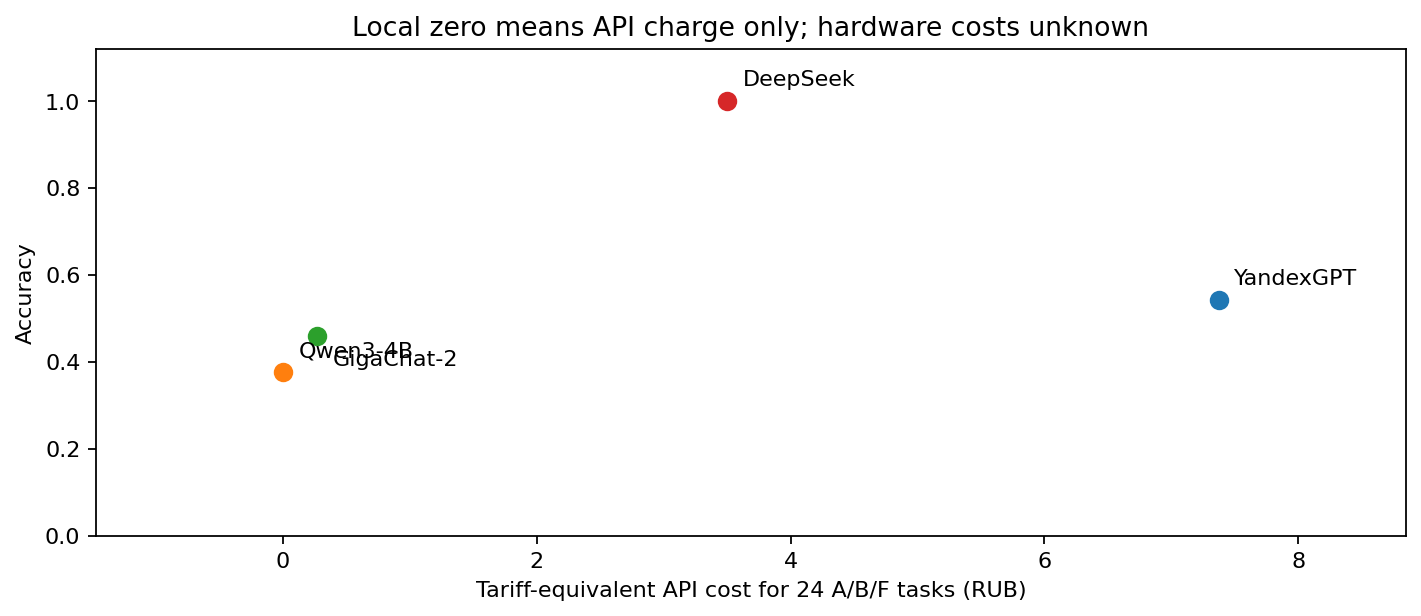

In [30]:
figure('cost_accuracy.png')

**Что видно и чего здесь нет.** На A/B/F DeepSeek точнее Yandex и дешевле по тарифному эквиваленту: около 3.50 против 7.37 рубля за 24 запроса. Это не означает, что весь прогон DeepSeek дешевле: все 344 вызова стоили по usage около 437.23 рубля против 248.46 у Yandex. На рисунке нет стоимости оборудования, реальных банковских списаний и резервов сетевых попыток — они отдельно раскрыты в таблице.

**Далее — сведения о локальной машине и памяти.** Из сохранённого мониторинга выводятся CPU, RAM, пиковый RSS процесса и память всего GPU. Значения в bytes нужно делить на 1024³ для GiB; sampled peak означает максимум среди измерений, а не гарантированный непрерывный пик.

In [31]:
hardware=read_json(ROOT/'analysis/local/hardware.json')
print(json.dumps({k:v for k,v in hardware.items() if k!='samples'},ensure_ascii=False,indent=2))

{
  "cpu": "Intel64 Family 6 Model 151 Stepping 5, GenuineIntel",
  "logical_cpus": 12,
  "ram_total_bytes": 34104377344,
  "sampling_scope": "All/resume invocation; pilot and main before monitoring excluded. VRAM is whole device including desktop, not process allocation.",
  "peak_rss_bytes": 3241472000,
  "peak_device_used_mib": 5458
}


**Как интерпретировать результат.** На A/B/F DeepSeek по тарифу дешевле Yandex и точнее, но весь прогон DeepSeek дороже из-за длинных рассуждений и незавершённой классификации. У Giga тарифный эквивалент около 3.95 рубля за все 344 ответа, фактических покупок не было: использовалась бесплатная квота. У Qwen нулевая цена API не означает бесплатное оборудование или электричество.

В мониторинге Qwen около 3.02 GiB sampled RSS, а занятая память всего GPU — 5458 MiB. Последняя включает рабочий стол. Средняя скорость зависит также от длины ответа, кэша, сети и режима рассуждений, поэтому не является чистым сравнением вычислительных архитектур.

## 12 Ручная проверка и ограничения

Ни одна отсутствующая оценка не заменяется нулём. B-вердикт проверен автоматически, обоснование 0–2 — отдельно. C и методология D: два участника независимо, смешанные ответы разных моделей, без ключа соответствия; затем kappa, уточнение рубрики при κ<0.6, разрешение разногласий. Отдельные пакеты по модели сами по себе не обеспечивают слепоту.

Ограничения: восемь задач на тип; F-пары зависимы; публичный breast cancer мог быть в обучении; единственный train5/train20; режимы reasoning и квантование различаются; банк draft и эталоны требуют человеческой проверки; доверительный интервал не учитывает все источники неопределённости; нет полноценных ручных итогов C/D. Поэтому обобщать на все ML-задачи и клиническое применение нельзя.

**Что показывает статус ручной проверки.** Для B-объяснений, выбора метода C и методологии программ D нужны две независимые оценки участников. `required` — сколько ответов нужно оценить, `paired_reviews` — сколько уже имеют обе оценки. `kappa` измеряет согласие оценщиков с учётом случайного совпадения.

Этот блок читает зафиксированные формы и ничего не выставляет за людей. Наличие автоматической проверки чисел не делает ручную оценку выполненной.

In [32]:
readable_manual(read_json(OUT/'manual_status.json'))

,Модель,Тип,Требуется ответов,Ответов с двумя оценками,Статус,Коэффициент согласия
0,YandexGPT,B,8,0,pending,None
1,YandexGPT,C,7,0,pending,None
2,YandexGPT,D,8,0,pending,None
3,Qwen3-4B,B,8,0,pending,None
4,Qwen3-4B,C,7,0,pending,None
5,Qwen3-4B,D,8,0,pending,None
6,GigaChat-2,B,8,0,pending,None
7,GigaChat-2,C,7,0,pending,None
8,GigaChat-2,D,8,0,pending,None
9,DeepSeek,B,8,0,pending,None


**Почему часть полей пуста.** В репозитории нет заполненных пар независимых оценок. Поэтому kappa не определена, статус pending, а общая accuracy 39 задач не рассчитывается. Это состояние незавершённой проверки, а не нулевое качество ответов C/D.

Для настоящей слепой проверки ответы разных моделей нужно перемешать и скрыть их происхождение. Предварительный разбор ассистента не равен двум независимым человеческим оценкам. Текущие автоматические выводы остаются полезными, если не расширять их на непроверенные части.

## 13 Как сформулировать результат на защите

На нашем фиксированном банке DeepSeek существенно лучше остальных по итоговым A/B/F, но ограничение reasoning-бюджета делает его ненадёжным как классификатор строк в выбранном режиме. Qwen конкурентна few-shot, особенно при 5 примерах; это не подтверждает, что любой маленькой модели достаточно для любого ML. Классическая LR на 20 примерах даёт F1≈0.912 и не имеет проблемы незавершённой генерации. Ни одна confidence не заменяет проверку, особенно когда объяснение противоречит answer.

Практически: расчёты сверять формулой/кодом; советы по методам проверять на утечку и схему оценки; сгенерированный код запускать и отдельно проверять методологию; табличную классификацию сравнивать с простыми baseline. Численно подтверждённые результаты отделять от гипотез о причинах.

Подробный маршрут, объяснение каждого числа, формулы, разбор ошибок, 12 вопросов методички и дополнительные вопросы: `docs/defense_guide.md` / `docs/defense_guide.html`.

## 14 Необязательная живая проверка подключения

**По умолчанию выключена.** Не входит в Run All и оригинальные оценки. Если преподаватель попросит показать реальный вызов, установите LIVE=True и выберите модель. Может расходовать токены/квоту; ключи читаются только из локального окружения, не вписывайте их в блокнот. Результат сохраняется отдельно. Новый вызов не гарантирует побитовое совпадение исторического ответа. Для Qwen используйте отдельный local_runner с уже скачанными весами и CUDA.

**Что делает последняя ячейка.** При `LIVE=False` она только печатает сообщение. Если вручную поставить `LIVE=True`, можно отправить один новый диагностический вопрос выбранной облачной модели. Это уже сетевое действие с возможным расходом токенов; ключ читается из локального окружения, а не из текста блокнота.

**Зачем она нужна.** При просьбе показать подключение можно сделать отдельный текущий вызов, не перезапуская весь эксперимент и не заменяя старые ответы.

In [33]:
LIVE=False
LIVE_MODEL='GigaChat-2'
if LIVE:
    from defense_live_probe import probe
    print(json.dumps(probe(LIVE_MODEL,consent=True),ensure_ascii=False,indent=2))
else:
    print('Живой вызов отключён. При Run All токены не расходуются.')

Живой вызов отключён. При Run All токены не расходуются.


**Что подтверждено сейчас.** Сообщение «живой вызов отключён» означает, что при выполнении этого блокнота новые токены моделей не расходовались. Все основные таблицы и рисунки построены по прежним данным.

Новый live-вызов подтвердил бы доступ к сервису в текущий момент, но сам по себе не доказал бы исторические запуски. Для них используются журналы, их контрольные суммы, история регистрации и при необходимости внешняя статистика провайдера.